# Case Study - CRC (SRM colorectal cancer data)

This is case study using the experimental data from [Surinova et al. (2015)](https://pmc.ncbi.nlm.nih.gov/articles/PMC4568950/).

The dataset is available at: TODO (data is impossible to get online. Need to post the MSstats copy somewhere)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
import networkx as nx
import matplotlib.pyplot as plt

import matplotlib
from matplotlib.collections import LineCollection
from scipy.stats import gaussian_kde

import json
import scipy
import scipy.cluster.hierarchy as sch
import sys
import os
current_dir = os.getcwd()
sys.path.append(os.path.join(os.path.dirname(current_dir), 'code'))
import pickle

from tqdm import tqdm


import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from protmapper import uniprot_client
from indra.databases import hgnc_client

from MSquantSim.simulate import simulate_using_copula, simulate_using_tvae, \
    simulate_using_per_protein
from MSquantSim.downstreamanalysis import train_rf, get_pca_explained_variance
from MSquantSim.similarity_scores import plot_corr, similarity_across_simulations

import warnings
warnings.filterwarnings('ignore')

import os

def hgnc_converter(id, mnemonic_id=False):
    if mnemonic_id:
        uniprot_id = uniprot_client.get_id_from_mnemonic(id)
    else:
        uniprot_id = id
    hgnc_id = uniprot_client.get_hgnc_id(uniprot_id)
    hgnc_name = hgnc_client.get_hgnc_name(hgnc_id)
    return hgnc_name

Plasma samples were subjected to parallel N-glycoprotein
extraction in a 96-well format, followed by targeted Selected Reaction Monitoring (SRM)
quantification of 67 candidate proteins by SRM. PSMs were summarized into protein-level
summaries by MSstatsTMT. 

## Process MSstats protein-level data

In [2]:
crc_input = pd.read_csv('../data/crc/CRC_training_protein_level_data.csv')
crc_validation_input = pd.read_csv('../data/crc/CRC_validation_protein_level_data.csv')
crc_validation_input.drop(columns=['Run', 'BioReplicate'], axis=1, inplace=True)
crc_input.head()

,Run,A1AG2,AFM,AHSG,ANT3,AOC3,APOB,ATRN,BTD,C20orf3,...,SERPINA1,SERPINA3,SERPINA6,SERPINA7,THBS1,TIMP1,VTN,VWF,Condition,BioReplicate
0,CRC_P1A10,14.238157,16.103019,19.951792,17.207936,10.032169,15.544774,14.383388,16.283071,10.667779,...,18.061091,14.218036,15.796849,13.581848,13.995686,11.578754,12.081352,10.661031,CRC,CRC_P1A10
1,CRC_P1A2,15.024111,16.020714,19.715919,17.297900,9.034144,15.131883,13.981723,16.249189,10.703279,...,17.610188,14.832327,15.815397,13.138445,13.707714,11.960974,12.838407,10.778432,CRC,CRC_P1A2
2,CRC_P1A4,15.631364,16.143800,19.710849,17.596254,10.381880,15.955302,14.635355,16.499158,11.183873,...,18.539972,15.308726,16.401770,13.742330,15.636962,12.155842,12.313155,11.185271,CRC,CRC_P1A4
3,CRC_P1A6,15.401365,16.276415,19.704377,17.422504,9.502960,15.714932,14.060700,16.277732,9.972982,...,17.401414,14.254241,16.310491,13.936894,15.517268,12.379265,10.679166,10.887855,CRC,CRC_P1A6
4,CRC_P1B12,16.003158,16.958207,20.420334,17.988199,9.648502,16.247330,14.203595,16.541422,12.581556,...,17.448008,16.231911,16.485833,14.167134,15.129106,12.169116,14.506106,11.254175,CRC,CRC_P1B12


In [142]:
crc_input.groupby("Condition").size()

Condition
CRC        100
Healthy    100
dtype: int64

In [143]:
crc_validation_input.groupby("Condition").size()

Condition
CRC        202
Control     67
dtype: int64

In [3]:
# Split into health and disease
crc_healthy = crc_input[crc_input['Condition'] == 'Healthy'].drop(columns=['Condition', 'Run', 'BioReplicate'])
crc_disease = crc_input[crc_input['Condition'] == 'CRC'].drop(columns=['Condition', 'Run', 'BioReplicate'])

In [4]:
train_test = crc_input.iloc[:,1:]
train_test.loc[:, "type"] = "train"
valid_test = crc_validation_input.iloc[:,:-1]
valid_test.loc[:, "type"] = "validation"

combined = pd.concat([train_test, valid_test], axis=0)

In [5]:
# Wide -> long, one row per (run, protein)
protein_cols = [c for c in combined.columns if c not in ["Condition", "BioReplicate", "type"]]

combined_long = (
    combined.reset_index(drop=True)
        .rename_axis("run")
        .reset_index()
        .melt(id_vars=["run", "type"], value_vars=protein_cols,
              var_name="Protein", value_name="Abundance")
)
combined_long.head()


,run,type,Protein,Abundance
0,0,train,A1AG2,14.238157
1,1,train,A1AG2,15.024111
2,2,train,A1AG2,15.631364
3,3,train,A1AG2,15.401365
4,4,train,A1AG2,16.003158


INFO: [2026-08-25 11:36:01] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO: [2026-08-25 11:36:01] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


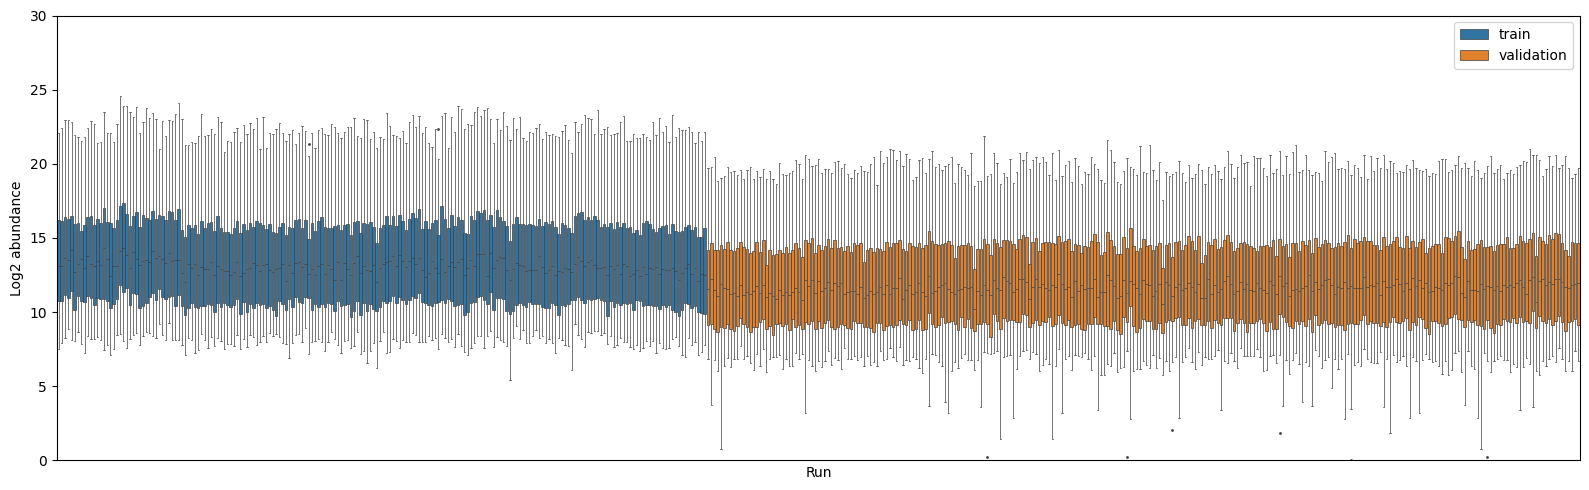

In [101]:
# One boxplot per run, colored by train/validation
run_order = combined_long.drop_duplicates("run").sort_values(["type", "run"])["run"].tolist()

fig, ax = plt.subplots(figsize=(16, 5))
sns.boxplot(data=combined_long, x="run", y="Abundance", hue="type", order=run_order,
            dodge=False, fliersize=1, linewidth=.5, ax=ax)
ax.set_xticks([])
ax.set_xlabel("Run")
ax.set_ylabel("Log2 abundance")
ax.set_ylim(0,30)
ax.legend(title="")
plt.tight_layout()
plt.show()




## Normalize runs

The per-run boxplots above show two problems: run-to-run shifts within each cohort
(~0.4 log2 SD) and a ~1.4 log2 offset between the training and validation cohorts.
Since the validation set is used as the held-out test set for the random forests
below, that offset has to go or the classifier sees a systematic shift at test time.

Equalize-medians normalization (the MSstats convention): shift every run so its
median log2 abundance matches the median of all run medians. Train and validation
runs are pooled against a single common reference, so the cohort offset is removed
along with the within-cohort run shifts. Median-based, so the handful of extreme
negative values (10 across all runs, mostly PIGR) do not distort the factors.

In [108]:
def align_cohort(combined_long, value="Abundance", type_col="type",
                 test_label="validation", train_label="train"):
    """Single additive constant so the test median matches train."""
    med = combined_long.groupby(type_col)[value].median()
    offset = med[train_label] - med[test_label]
 
    is_test = combined_long[type_col] == test_label
    out = combined_long.copy()
    out.loc[is_test, value] = out.loc[is_test, value] + offset
    return out, offset

combined_long_norm, _ = align_cohort(combined_long)


INFO: [2026-08-25 11:39:42] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO: [2026-08-25 11:39:42] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


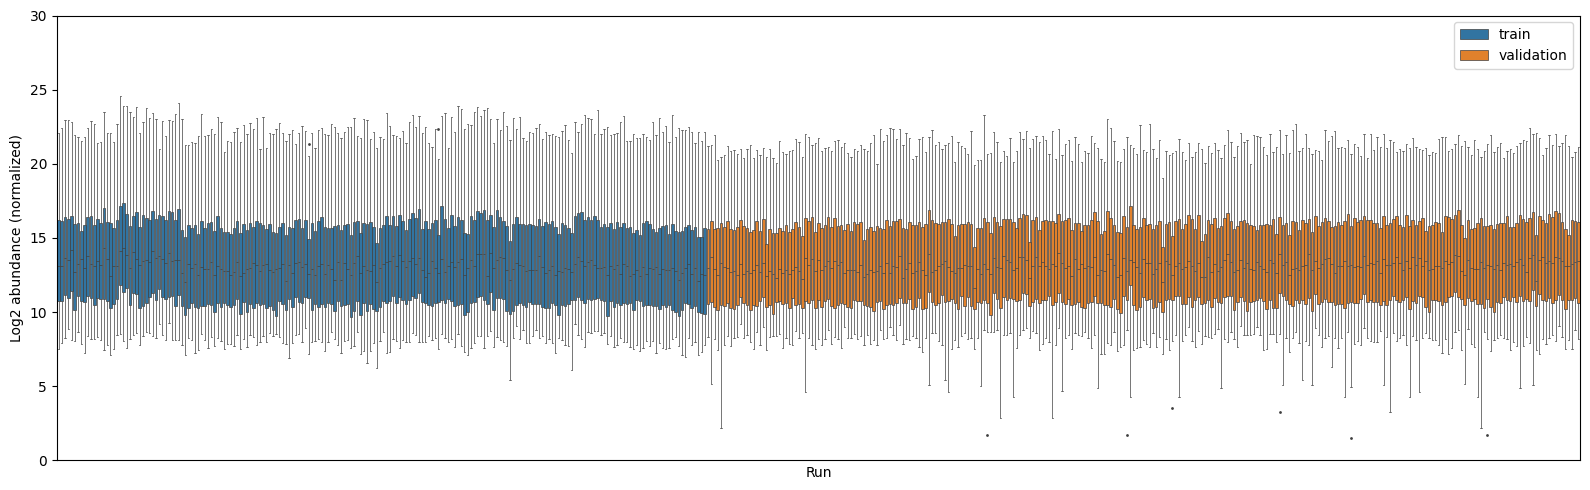

In [109]:
# Same boxplot as above, after normalization
fig, ax = plt.subplots(figsize=(16, 5))
sns.boxplot(data=combined_long_norm, x="run", y="Abundance", hue="type", order=run_order,
            dodge=False, fliersize=1, linewidth=.5, ax=ax)
ax.set_xticks([])
ax.set_xlabel("Run")
ax.set_ylabel("Log2 abundance (normalized)")
ax.set_ylim(0, 30)
ax.legend(title="")
plt.tight_layout()
plt.show()

In [111]:
combined_long_norm

,run,type,Protein,Abundance
0,0,train,A1AG2,14.238157
1,1,train,A1AG2,15.024111
2,2,train,A1AG2,15.631364
3,3,train,A1AG2,15.401365
4,4,train,A1AG2,16.003158
...,...,...,...,...
31418,464,validation,VWF,9.940156
31419,465,validation,VWF,11.657141
31420,466,validation,VWF,11.207491
31421,467,validation,VWF,11.294707


In [6]:
crc_input_raw = globals().get("crc_input_raw", crc_input.copy())
crc_validation_input_raw = globals().get(
    "crc_validation_input_raw", crc_validation_input.copy()
)
 
train_median = np.nanmedian(crc_input_raw[protein_cols].to_numpy(dtype=float))
valid_median = np.nanmedian(
    crc_validation_input_raw[protein_cols].to_numpy(dtype=float)
)
offset = train_median - valid_median
 
crc_input = crc_input_raw.copy()
crc_validation_input = crc_validation_input_raw.copy()
crc_validation_input[protein_cols] = (
    crc_validation_input_raw[protein_cols].to_numpy(dtype=float) + offset
)
 
print(f"train median {train_median:.3f} | validation median {valid_median:.3f}")
print(f"validation shifted by {offset:+.3f} log2 units")
 
# Re-derive the condition splits so the simulations below use normalized data
crc_healthy = crc_input[crc_input["Condition"] == "Healthy"].drop(
    columns=["Condition", "Run", "BioReplicate"]
)
crc_disease = crc_input[crc_input["Condition"] == "CRC"].drop(
    columns=["Condition", "Run", "BioReplicate"]
)

train median 13.080 | validation median 11.640
validation shifted by +1.440 log2 units


## Simulations
### Copula
#### Single simulation

In [54]:
copula_sim_healthy = simulate_using_copula(
    crc_healthy, num_simulations=1, 
    samples_per_simulation=len(crc_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

copula_sim_disease = simulate_using_copula(
    crc_disease, num_simulations=1, 
    samples_per_simulation=len(crc_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

INFO: [2026-08-25 09:31:02] copulas.multivariate.gaussian - Fitting GaussianMultivariate()
INFO: [2026-08-25 09:31:10] copulas.multivariate.gaussian - Fitting GaussianMultivariate()


#### Multiple simulations

In [113]:
n_sims = 100

copula_sim_crc_healthy_multi = simulate_using_copula(
    crc_healthy, num_simulations=n_sims, 
    samples_per_simulation=len(crc_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

copula_sim_crc_disease_multi = simulate_using_copula(
    crc_disease, num_simulations=n_sims, 
    samples_per_simulation=len(crc_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

Running copula simulations: 100%|██████████| 100/100 [00:31<00:00,  3.15it/s]


In [127]:
with open("../../data/CRC_data/results/COPULA_CRC_healthy.pkl", "wb") as f:
    pickle.dump(copula_sim_crc_healthy_multi, f)
with open("../../data/CRC_data/results/COPULA_CRC_disease.pkl", "wb") as f:
    pickle.dump(copula_sim_crc_disease_multi, f)

### TVAE

#### Single simulation

In [ ]:
tvae_sim_healthy = simulate_using_tvae(
    crc_healthy, None, num_simulations=1,
    samples_per_simulation=len(crc_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

tvae_sim_disease = simulate_using_tvae(
    crc_disease, None, num_simulations=1,
    samples_per_simulation=len(crc_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

#### Multiple simulations

In [122]:
n_sims = 100

tvae_sim_crc_healthy_multi = simulate_using_tvae(
    crc_healthy, None, num_simulations=n_sims,
    samples_per_simulation=len(crc_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

tvae_sim_crc_disease_multi = simulate_using_tvae(
    crc_disease, None, num_simulations=n_sims,
    samples_per_simulation=len(crc_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

INFO: [2026-08-25 11:47:16] sdv.metadata.single_table - Detected metadata:
INFO: [2026-08-25 11:47:16] sdv.metadata.single_table - {
    "METADATA_SPEC_VERSION": "SINGLE_TABLE_V1",
    "columns": {
        "A1AG2": {
            "sdtype": "numerical"
        },
        "AFM": {
            "sdtype": "numerical"
        },
        "AHSG": {
            "sdtype": "numerical"
        },
        "ANT3": {
            "sdtype": "numerical"
        },
        "AOC3": {
            "sdtype": "numerical"
        },
        "APOB": {
            "sdtype": "numerical"
        },
        "ATRN": {
            "sdtype": "numerical"
        },
        "BTD": {
            "sdtype": "numerical"
        },
        "C20orf3": {
            "sdtype": "numerical"
        },
        "CADM1": {
            "sdtype": "numerical"
        },
        "CD163": {
            "sdtype": "numerical"
        },
        "CD44": {
            "sdtype": "numerical"
        },
        "CDH5": {
            "sdtype": "n

In [128]:
with open("../../data/CRC_data/results/TVAE_CRC_healthy.pkl", "wb") as f:
    pickle.dump(tvae_sim_crc_healthy_multi, f)
with open("../../data/CRC_data/results/TVAE_CRC_disease.pkl", "wb") as f:
    pickle.dump(tvae_sim_crc_disease_multi, f)

### Per-protein

#### Single simulation

In [10]:
pprotein_sim_healthy = simulate_using_per_protein(
    crc_healthy, num_simulations=1,
    samples_per_simulation=len(crc_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

pprotein_sim_disease = simulate_using_per_protein(
    crc_disease, num_simulations=1,
    samples_per_simulation=len(crc_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

#### Multiple simulations

In [123]:
n_sims = 100

pprotein_sim_crc_healthy_multi = simulate_using_per_protein(
    crc_healthy, num_simulations=n_sims,
    samples_per_simulation=len(crc_healthy), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

pprotein_sim_crc_disease_multi = simulate_using_per_protein(
    crc_disease, num_simulations=n_sims,
    samples_per_simulation=len(crc_disease), # Set to size of input data to mirror variability
    output_dir=None, output_prefix='simulated',
    return_data=True, random_state=2
)

Running per-protein simulations: 100%|██████████| 100/100 [00:00<00:00, 2609.94it/s]


In [129]:
with open("../../data/CRC_data/results/PPROTEIN_CRC_healthy.pkl", "wb") as f:
    pickle.dump(pprotein_sim_crc_healthy_multi, f)
with open("../../data/CRC_data/results/PPROTEIN_CRC_disease.pkl", "wb") as f:
    pickle.dump(pprotein_sim_crc_disease_multi, f)

### Get pilot/historical data from past similar experiment

In [2]:
data = pd.read_csv('../casestudy/crc/data/crc_silvia_data.csv')
data.head()

,A1AG2,AFM,AHSG,ANT3,AOC3,APOB,ATRN,BTD,C20orf3,CADM1,...,Q5JNX2,SERPINA1,SERPINA3,SERPINA6,SERPINA7,THBS1,TIMP1,VTN,VWF,Condition
0,14.238157,16.103019,19.951792,17.207936,10.032169,15.544774,14.383388,16.283071,10.667779,9.653029,...,19.028130,18.061091,14.218036,15.796849,13.581848,13.995686,11.578754,12.081352,10.661031,CRC
1,15.024111,16.020714,19.715919,17.297900,9.034144,15.131883,13.981723,16.249189,10.703279,9.624991,...,19.862536,17.610188,14.832327,15.815397,13.138445,13.707714,11.960974,12.838407,10.778432,CRC
2,15.631364,16.143800,19.710849,17.596254,10.381880,15.955302,14.635355,16.499158,11.183873,10.323191,...,19.501773,18.539972,15.308726,16.401770,13.742330,15.636962,12.155842,12.313155,11.185271,CRC
3,15.401365,16.276415,19.704377,17.422504,9.502960,15.714932,14.060700,16.277732,9.972982,9.994209,...,19.984664,17.401414,14.254241,16.310491,13.936894,15.517268,12.379265,10.679166,10.887855,CRC
4,16.003158,16.958207,20.420334,17.988199,9.648502,16.247330,14.203595,16.541422,12.581556,9.607492,...,20.467453,17.448008,16.231911,16.485833,14.167134,15.129106,12.169116,14.506106,11.254175,CRC


## Evaluate simulations

In [7]:
with open("../../data/CRC_data/results/COPULA_CRC_healthy.pkl", "rb") as f:
    copula_sim_crc_healthy_multi = pickle.load(f)
with open("../../data/CRC_data/results/COPULA_CRC_disease.pkl", "rb") as f:
    copula_sim_crc_disease_multi = pickle.load(f)
with open("../../data/CRC_data/results/TVAE_CRC_healthy.pkl", "rb") as f:
    tvae_sim_crc_healthy_multi = pickle.load(f)
with open("../../data/CRC_data/results/TVAE_CRC_disease.pkl", "rb") as f:
    tvae_sim_crc_disease_multi = pickle.load(f)
with open("../../data/CRC_data/results/PPROTEIN_CRC_healthy.pkl", "rb") as f:
    pprotein_sim_crc_healthy_multi = pickle.load(f)
with open("../../data/CRC_data/results/PPROTEIN_CRC_disease.pkl", "rb") as f:
    pprotein_sim_crc_disease_multi = pickle.load(f)

### Correlation Heatmaps

#### Experimental data

In [56]:
def plot_corr(
    df: pd.DataFrame,
    size: float = 10,
    method: str = "pearson",
    cmap: str = "RdBu_r",
):
    """
    Professional, label-free correlation heatmap (lower triangle),
    optimized for large feature sets and colorblind safety.
    """
    # Keep numeric columns only
    x = df.select_dtypes(include=[np.number])
    if x.shape[1] < 2:
        raise ValueError("Need at least 2 numeric columns.")

    corr = x.corr(method=method)

    # Mask upper triangle + diagonal
    mask = np.triu(np.ones_like(corr, dtype=bool))
    corr_plot = corr.mask(mask)

    fig, ax = plt.subplots(figsize=(size, size), dpi=150)

    im = ax.imshow(
        corr_plot.to_numpy(),
        vmin=-1,
        vmax=1,
        cmap=cmap,
        interpolation="nearest",
    )

    # Remove all ticks and labels
    ax.set_xticks([])
    ax.set_yticks([])

    # Optional subtle grid for structure (can remove if you want ultra-clean)
    n = corr.shape[0]
    ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", linewidth=0.4, alpha=.2)
    ax.tick_params(which="minor", bottom=False, left=False)

    # Colorbar
    cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_ticks([-1, -0.5, 0, 0.5, 1])
    cbar.ax.tick_params(labelsize=10)
    cbar.set_label("Correlation", fontsize=11)

    fig.tight_layout()
    return fig, ax

(<Figure size 750x750 with 2 Axes>, <Axes: >)

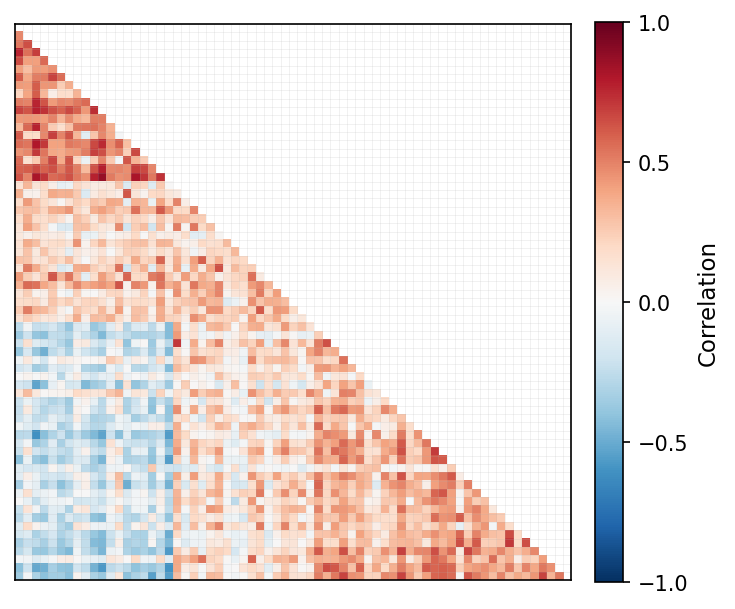

In [57]:
X = crc_healthy.corr().values
X[np.isnan(X)]= 0
d = sch.distance.pdist(X)   
L = sch.linkage(d, method='complete')
ind = sch.fcluster(L, 0.5*d.max(), 'distance')
columns = [crc_healthy.columns.tolist()[i] for i in list((np.argsort(ind)))]
columns_healthy = columns
crc_healthy = crc_healthy.reindex(columns, axis=1)
plot_corr(crc_healthy, size =5)

(<Figure size 750x750 with 2 Axes>, <Axes: >)

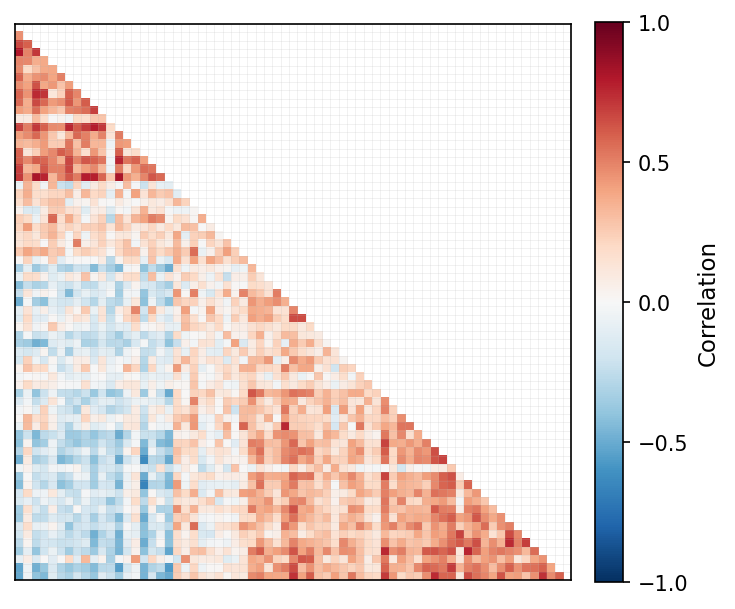

In [58]:
X = crc_disease.corr().values
X[np.isnan(X)]= 0
d = sch.distance.pdist(X)   
L = sch.linkage(d, method='complete')
ind = sch.fcluster(L, 0.5*d.max(), 'distance')
columns = [crc_disease.columns.tolist()[i] for i in list((np.argsort(ind)))]
columns_disease = columns
crc_disease = crc_disease.reindex(columns, axis=1)
plot_corr(crc_disease, size =5)

#### Per-protein

(<Figure size 750x750 with 2 Axes>, <Axes: >)

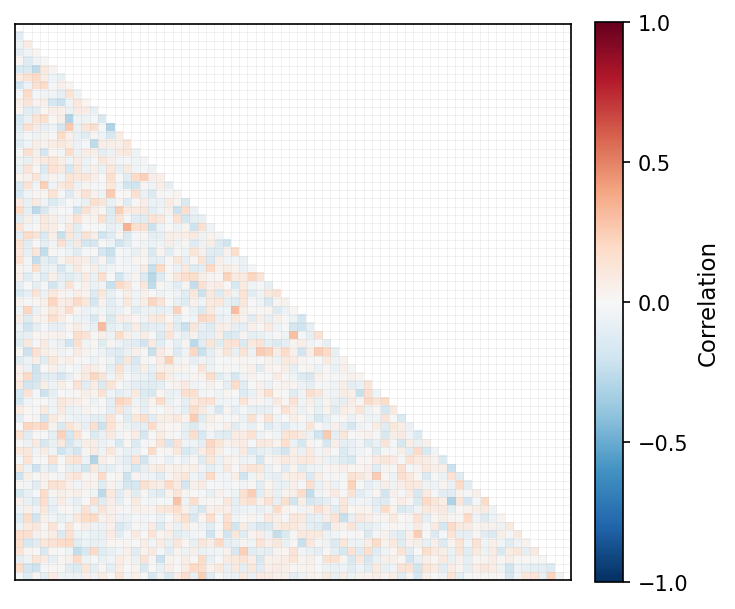

In [20]:
simpp0 = pprotein_sim_crc_healthy_multi[0]
simpp1 = pprotein_sim_crc_disease_multi[0]

simpp0 = simpp0.reindex(columns_healthy, axis=1)
plot_corr(simpp0, size = 5)

(<Figure size 750x750 with 2 Axes>, <Axes: >)

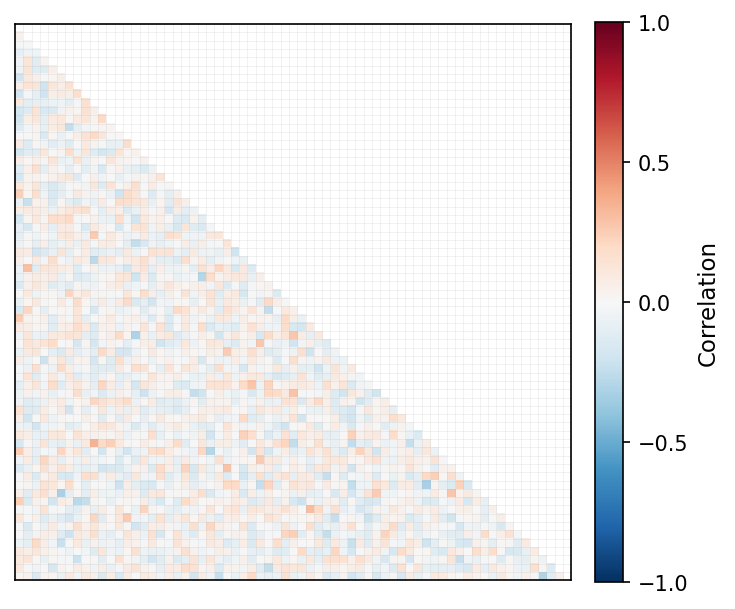

In [22]:
simpp1 = simpp1.reindex(columns_disease, axis=1)
plot_corr(simpp1, size = 5)

#### VAE

(<Figure size 750x750 with 2 Axes>, <Axes: >)

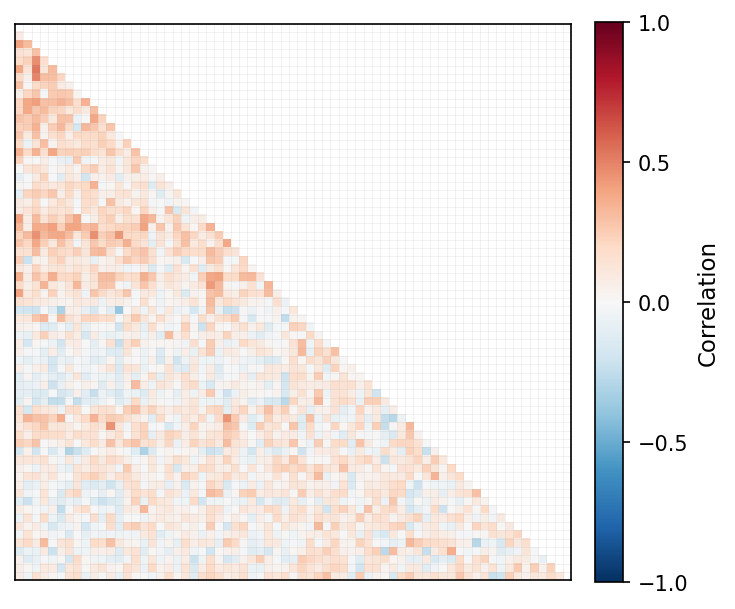

In [25]:
simtvae0 = tvae_sim_crc_healthy_multi[0]
simtvae1 = tvae_sim_crc_disease_multi[0]

simtvae0 = simtvae0.reindex(columns_healthy, axis=1)
plot_corr(simtvae0, size = 5)

(<Figure size 750x750 with 2 Axes>, <Axes: >)

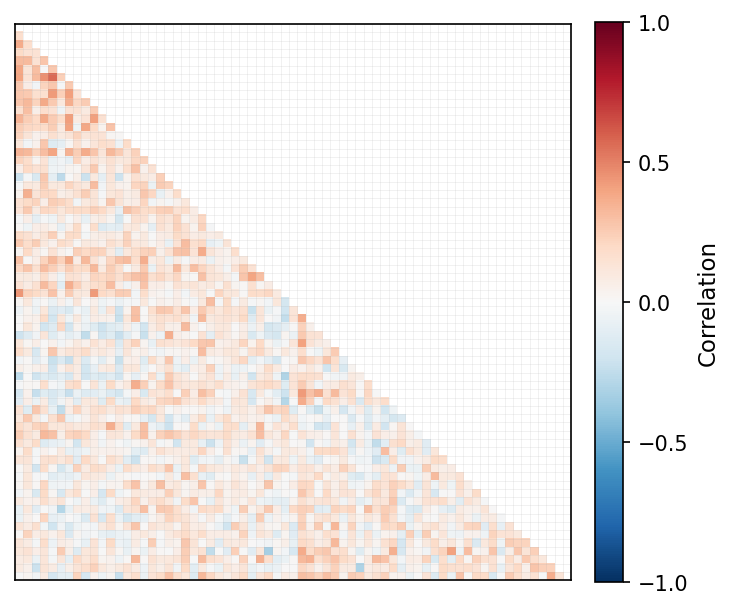

In [26]:
simtvae1 = simtvae1.reindex(columns_disease, axis=1)
plot_corr(simtvae1, size = 5)

#### Copula

(<Figure size 750x750 with 2 Axes>, <Axes: >)

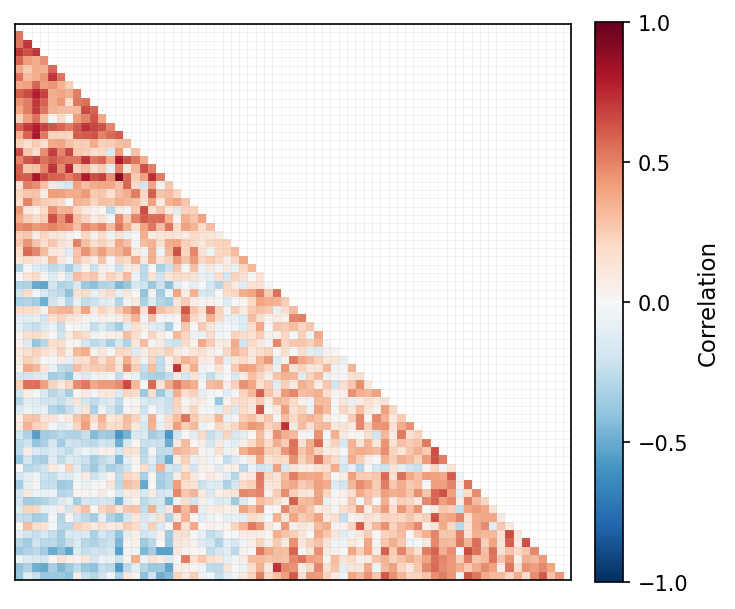

In [59]:
simco0 = copula_sim_crc_healthy_multi[0]
simco1 = copula_sim_crc_disease_multi[0]

simco0 = simco0.reindex(columns_healthy, axis=1)
plot_corr(simco0, size = 5)

(<Figure size 750x750 with 2 Axes>, <Axes: >)

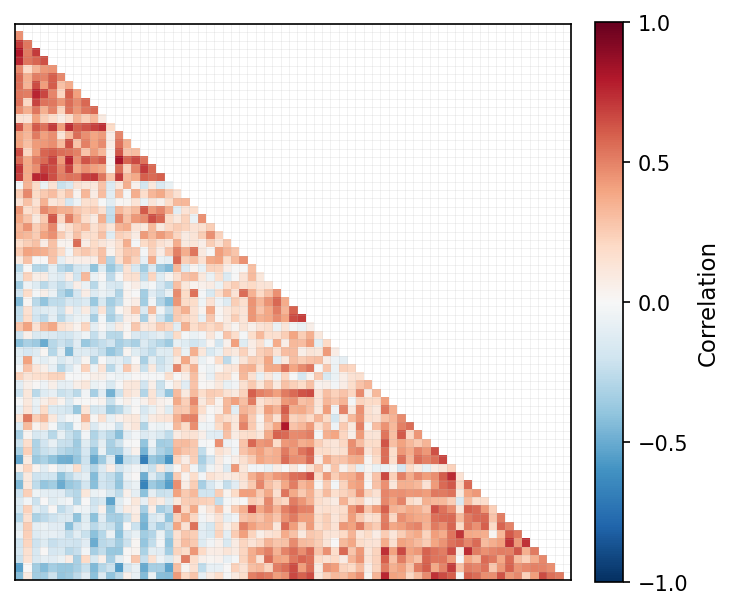

In [60]:
simco1 = simco1.reindex(columns_disease, axis=1)
plot_corr(simco1, size = 5)

#### Save correlation matrices for the paper figure

In [8]:
# Correlation matrices for the combined heatmap figure (simulation_comparison.ipynb).
# Proteins are ordered by clustering each group's experimental training data; the same
# order is used for every simulator in that group.
from MSquantSim.plotting import ordered_correlations

heatmap_data = {
    "healthy": {"Experimental": crc_healthy,
                "Per-protein": pprotein_sim_crc_healthy_multi[0],
                "Copula": copula_sim_crc_healthy_multi[0],
                "TVAE": tvae_sim_crc_healthy_multi[0]},
    "disease": {"Experimental": crc_disease,
                "Per-protein": pprotein_sim_crc_disease_multi[0],
                "Copula": copula_sim_crc_disease_multi[0],
                "TVAE": tvae_sim_crc_disease_multi[0]},
}
corr_matrices = {}
for group, sources in heatmap_data.items():
    order, corrs = ordered_correlations(sources)
    corr_matrices[f"{group}__proteins"] = np.array(order)
    for name, corr in corrs.items():
        corr_matrices[f"{group}__{name}"] = corr
np.savez_compressed("../data/results/CRC/correlation_matrices.npz", **corr_matrices)
print({k: v.shape for k, v in corr_matrices.items()})

{'healthy__proteins': (67,), 'healthy__Experimental': (67, 67), 'healthy__Per-protein': (67, 67), 'healthy__Copula': (67, 67), 'healthy__TVAE': (67, 67), 'disease__proteins': (67,), 'disease__Experimental': (67, 67), 'disease__Per-protein': (67, 67), 'disease__Copula': (67, 67), 'disease__TVAE': (67, 67)}


## Correlation statistics

In [61]:
crc_input = crc_input.drop(columns=['Run', 'BioReplicate'])

### Per-protein

In [ ]:
pp_sim_scores = similarity_across_simulations(pprotein_sim_crc_healthy_multi, 
                                              pprotein_sim_crc_disease_multi, 
                                              crc_input, "Condition", "Healthy", "CRC")

In [23]:
pp_avg_scores = {key: round(np.mean(values),4) for key, values in pp_sim_scores.items()}
print(pp_avg_scores.values())

dict_values([0.9986, -0.014, 0.9841, 0.8881, 0.7142])


In [27]:
pp_avg_scores = {key: round(np.std(values),4) for key, values in pp_sim_scores.items()}
print(pp_avg_scores.values())

dict_values([0.0003, 0.0209, 0.0007, 0.0379, 0.0113])


### TVAE

In [ ]:
tvae_sim_scores = similarity_across_simulations(tvae_sim_crc_healthy_multi, 
                                                tvae_sim_crc_disease_multi, 
                                                crc_input, "Condition", "Healthy", "CRC")

In [28]:
tvae_avg_scores = {key: round(np.mean(values),4) for key, values in tvae_sim_scores.items()}
print(tvae_avg_scores.values())

dict_values([0.9806, 0.4519, 0.9848, 0.8381, 0.8139])


In [29]:
tvae_avg_scores = {key: round(np.std(values),4) for key, values in tvae_sim_scores.items()}
print(tvae_avg_scores.values())

dict_values([0.0015, 0.0472, 0.0006, 0.0283, 0.0141])


### Copula

In [62]:
copula_sim_scores = similarity_across_simulations(copula_sim_crc_healthy_multi, 
                                                  copula_sim_crc_disease_multi, 
                                                  crc_input, "Condition", "Healthy", "CRC")

Evaluating simulations:   0%|          | 0/100 [00:00<?, ?it/s]/mnt/f/OneDrive - Northeastern University/Northeastern/Research/vartika_paper/MSquantSim/src/MSquantSim/similarity_scores.py:185: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(mean_val, inplace=True)
Evaluating simulations:  48%|████▊     | 48/100 [00:09<00:10,  5.01it/s]/home/devon/anaconda3/envs/msquantsim/lib/python3.11/site-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be remo

In [63]:
copula_avg_scores = {key: round(np.mean(values),4) for key, values in copula_sim_scores.items()}
print(copula_avg_scores.values())

dict_values([0.9967, 0.9637, 0.9867, 0.8641, 0.9528])


In [64]:
copula_avg_scores = {key: round(np.std(values),4) for key, values in copula_sim_scores.items()}
print(copula_avg_scores.values())

dict_values([0.0009, 0.0059, 0.0019, 0.0321, 0.0081])


##  Random Forest Classifier

In [8]:
n_samples = [5, 10, 25, 50, 75, 100]

### Experimental

In [9]:
experimental_input = {}

for i in n_samples:
    temp_list = list()
    for _ in range(100):
        experimental_healthy_results = crc_healthy.sample(n=i)
        experimental_disease_results = crc_disease.sample(n=i)
        
        experimental_healthy_results.loc[:, "Condition"] = "Control"
        experimental_disease_results.loc[:, "Condition"] = "CRC"
        
        temp_list.append(pd.concat([experimental_healthy_results, 
                                    experimental_disease_results], axis=0))
    
    experimental_input[i] = temp_list


In [146]:
experimental_model_accuracy = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        training_data = experimental_input[i][s]
        
        X = training_data.drop("Condition", axis=1)
        y = training_data["Condition"]
        temp_acc.append(train_rf(X, y, crc_validation_input))
    experimental_model_accuracy[i] = temp_acc
experimental_model_accuracy = pd.DataFrame(experimental_model_accuracy)

Running simulations: 100: 100%|██████████| 100/100 [07:02<00:00,  4.22s/it]


INFO: [2026-08-25 12:28:45] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO: [2026-08-25 12:28:45] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


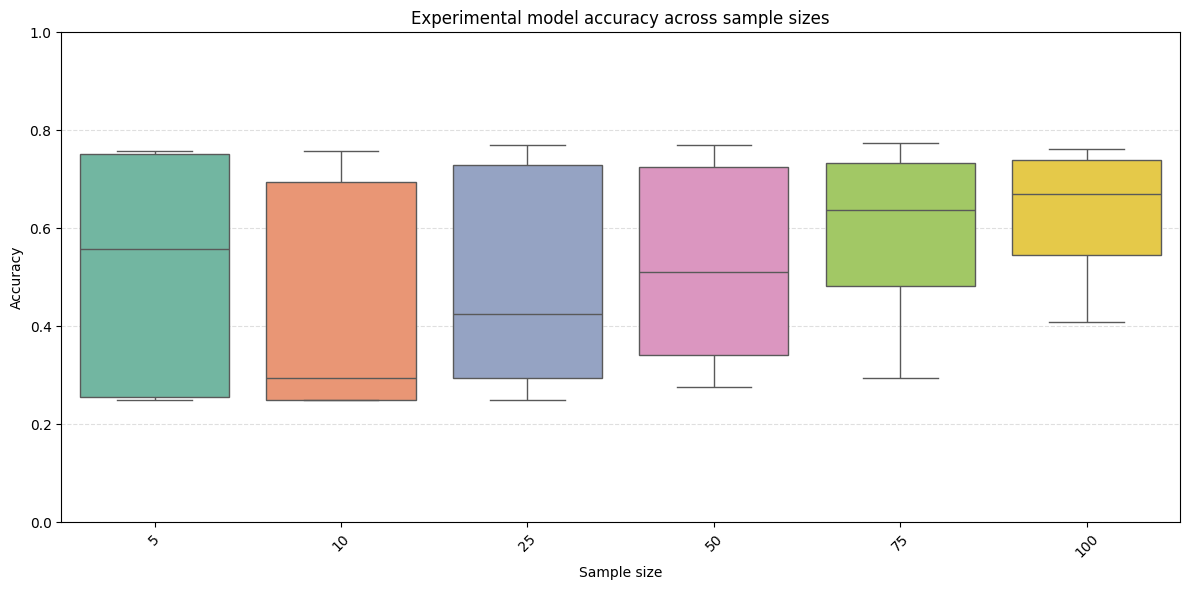

In [147]:
plt.figure(figsize=(12,6))
sns.boxplot(data=experimental_model_accuracy, palette="Set2")
plt.xlabel("Sample size")
plt.ylabel("Accuracy")
plt.title("Experimental model accuracy across sample sizes")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [165]:
experimental_model_accuracy.to_csv("../data/results/CRC/experimental_model_accuracy.csv")

### Copula

In [10]:
copula_input = {}

for i in n_samples:
    temp_list = list()
    for s in range(100):
        copula_healthy_results = copula_sim_crc_healthy_multi[s].sample(n=i)
        copula_disease_results = copula_sim_crc_disease_multi[s].sample(n=i)
        
        copula_healthy_results.loc[:, "Condition"] = "Control"
        copula_disease_results.loc[:, "Condition"] = "CRC"
        
        temp_list.append(pd.concat([copula_healthy_results, 
                                    copula_disease_results], axis=0))
    
    copula_input[i] = temp_list

In [150]:
copula_model_accuracy = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        training_data = copula_input[i][s]
        
        X = training_data.drop("Condition", axis=1)
        y = training_data["Condition"]
        temp_acc.append(train_rf(X, y, crc_validation_input))
    copula_model_accuracy[i] = temp_acc
copula_model_accuracy = pd.DataFrame(copula_model_accuracy)

Running simulations: 100: 100%|██████████| 100/100 [07:17<00:00,  4.37s/it]


In [164]:
copula_model_accuracy.to_csv("../data/results/CRC/copula_model_accuracy.csv")

INFO: [2026-08-25 12:56:54] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO: [2026-08-25 12:56:54] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


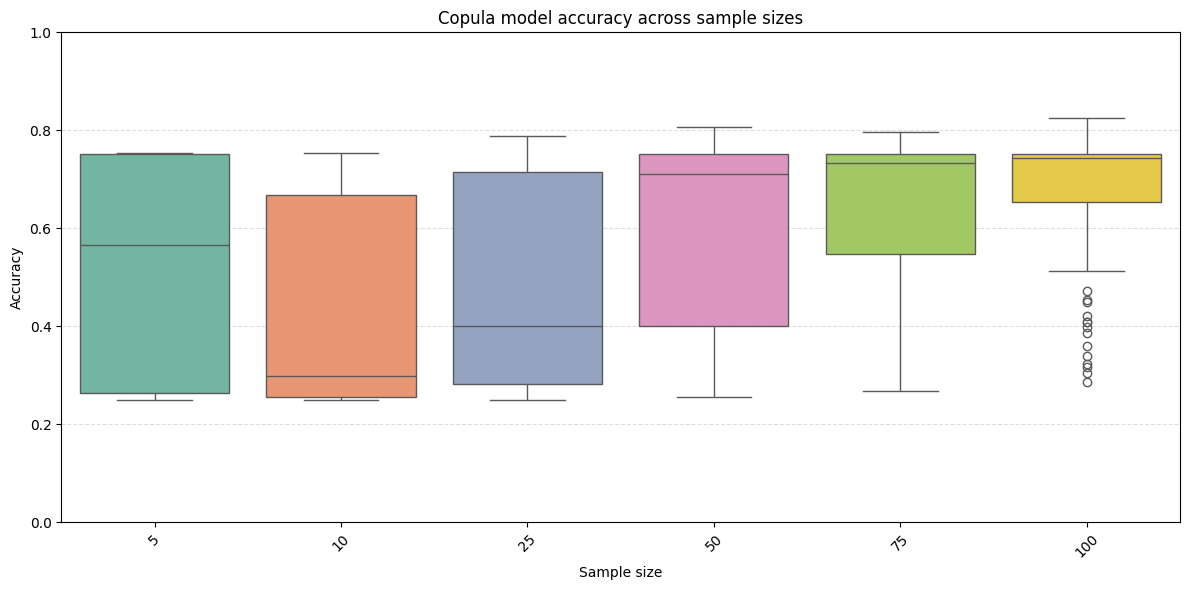

In [152]:
plt.figure(figsize=(12,6))
sns.boxplot(data=copula_model_accuracy, palette="Set2")
plt.xlabel("Sample size")
plt.ylabel("Accuracy")
plt.title("Copula model accuracy across sample sizes")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### TVAE

In [11]:
tvae_input = {}

for i in n_samples:
    temp_list = list()
    for s in range(100):
        tvae_healthy_results = tvae_sim_crc_healthy_multi[s].sample(n=i)
        tvae_disease_results = tvae_sim_crc_disease_multi[s].sample(n=i)
        
        tvae_healthy_results.loc[:, "Condition"] = "Control"
        tvae_disease_results.loc[:, "Condition"] = "CRC"
        
        temp_list.append(pd.concat([tvae_healthy_results, 
                                    tvae_disease_results], axis=0))
    
    tvae_input[i] = temp_list

In [154]:
tvae_model_accuracy = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        training_data = tvae_input[i][s]
        
        X = training_data.drop("Condition", axis=1)
        y = training_data["Condition"]
        temp_acc.append(train_rf(X, y, crc_validation_input))
    tvae_model_accuracy[i] = temp_acc
tvae_model_accuracy = pd.DataFrame(tvae_model_accuracy)

Running simulations: 100: 100%|██████████| 100/100 [06:22<00:00,  3.83s/it]


In [163]:
tvae_model_accuracy.to_csv("../data/results/CRC/tvae_model_accuracy.csv")

INFO: [2026-08-25 13:24:11] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO: [2026-08-25 13:24:11] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


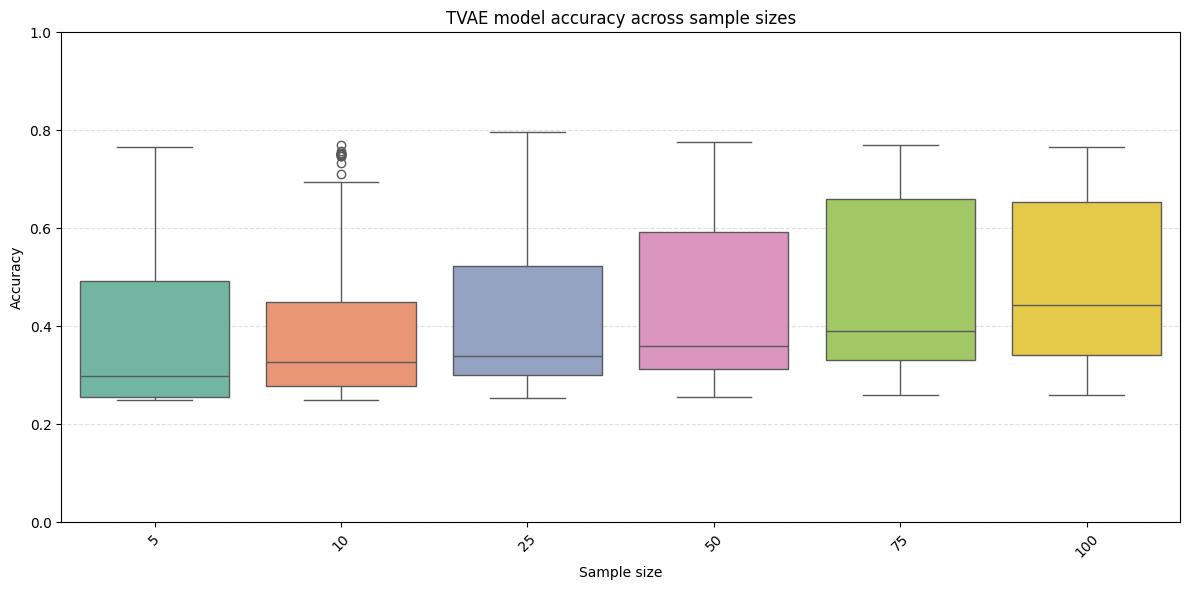

In [156]:
plt.figure(figsize=(12,6))
sns.boxplot(data=tvae_model_accuracy, palette="Set2")
plt.xlabel("Sample size")
plt.ylabel("Accuracy")
plt.title("TVAE model accuracy across sample sizes")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Per-protein

In [12]:
pprotein_input = {}

for i in n_samples:
    temp_list = list()
    for s in range(100):
        pprotein_healthy_results = pprotein_sim_crc_healthy_multi[s].sample(n=i)
        pprotein_disease_results = pprotein_sim_crc_disease_multi[s].sample(n=i)
        
        pprotein_healthy_results.loc[:, "Condition"] = "Control"
        pprotein_disease_results.loc[:, "Condition"] = "CRC"
        
        temp_list.append(pd.concat([pprotein_healthy_results, 
                                    pprotein_disease_results], axis=0))
    
    pprotein_input[i] = temp_list

In [159]:
pprotein_model_accuracy = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        training_data = pprotein_input[i][s]
        
        X = training_data.drop("Condition", axis=1)
        y = training_data["Condition"]
        temp_acc.append(train_rf(X, y, crc_validation_input))
    pprotein_model_accuracy[i] = temp_acc
pprotein_model_accuracy = pd.DataFrame(pprotein_model_accuracy)

Running simulations: 100: 100%|██████████| 100/100 [06:53<00:00,  4.13s/it]


In [162]:
pprotein_model_accuracy.to_csv("../data/results/CRC/pprotein_model_accuracy.csv")

INFO: [2026-08-25 13:58:51] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO: [2026-08-25 13:58:51] matplotlib.category - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


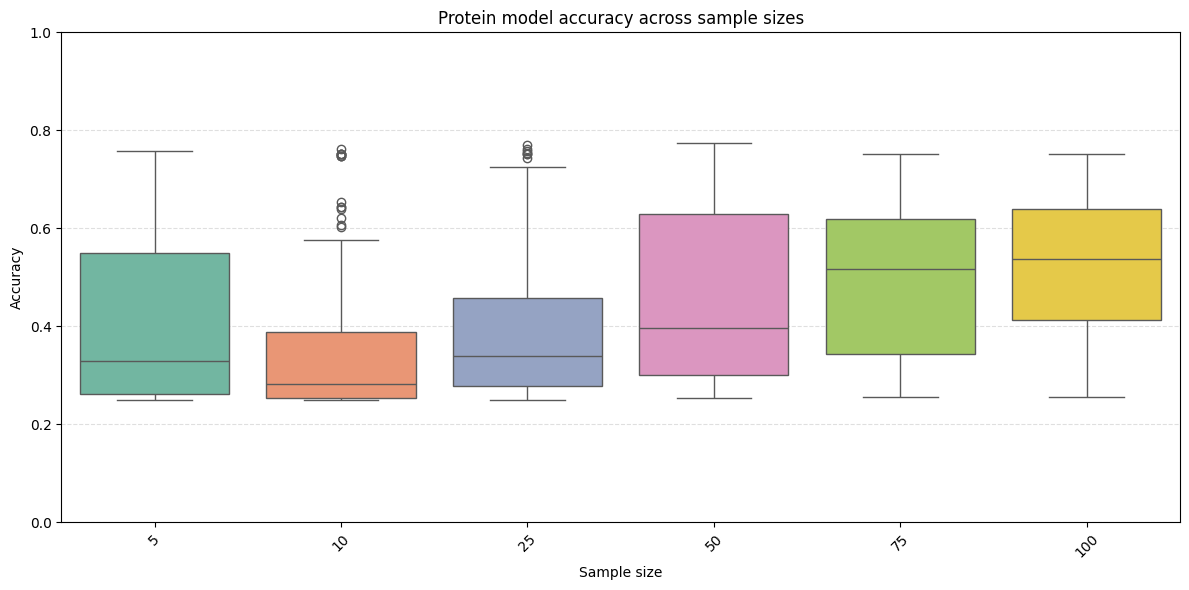

In [166]:
plt.figure(figsize=(12,6))
sns.boxplot(data=pprotein_model_accuracy, palette="Set2")
plt.xlabel("Sample size")
plt.ylabel("Accuracy")
plt.title("Protein model accuracy across sample sizes")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [4]:
experimental_model_accuracy = pd.read_csv("../data/results/CRC/experimental_model_accuracy.csv", index_col=0)
copula_model_accuracy = pd.read_csv("../data/results/CRC/copula_model_accuracy.csv", index_col=0)
tvae_model_accuracy = pd.read_csv("../data/results/CRC/tvae_model_accuracy.csv", index_col=0)
pprotein_model_accuracy = pd.read_csv("../data/results/CRC/pprotein_model_accuracy.csv", index_col=0)

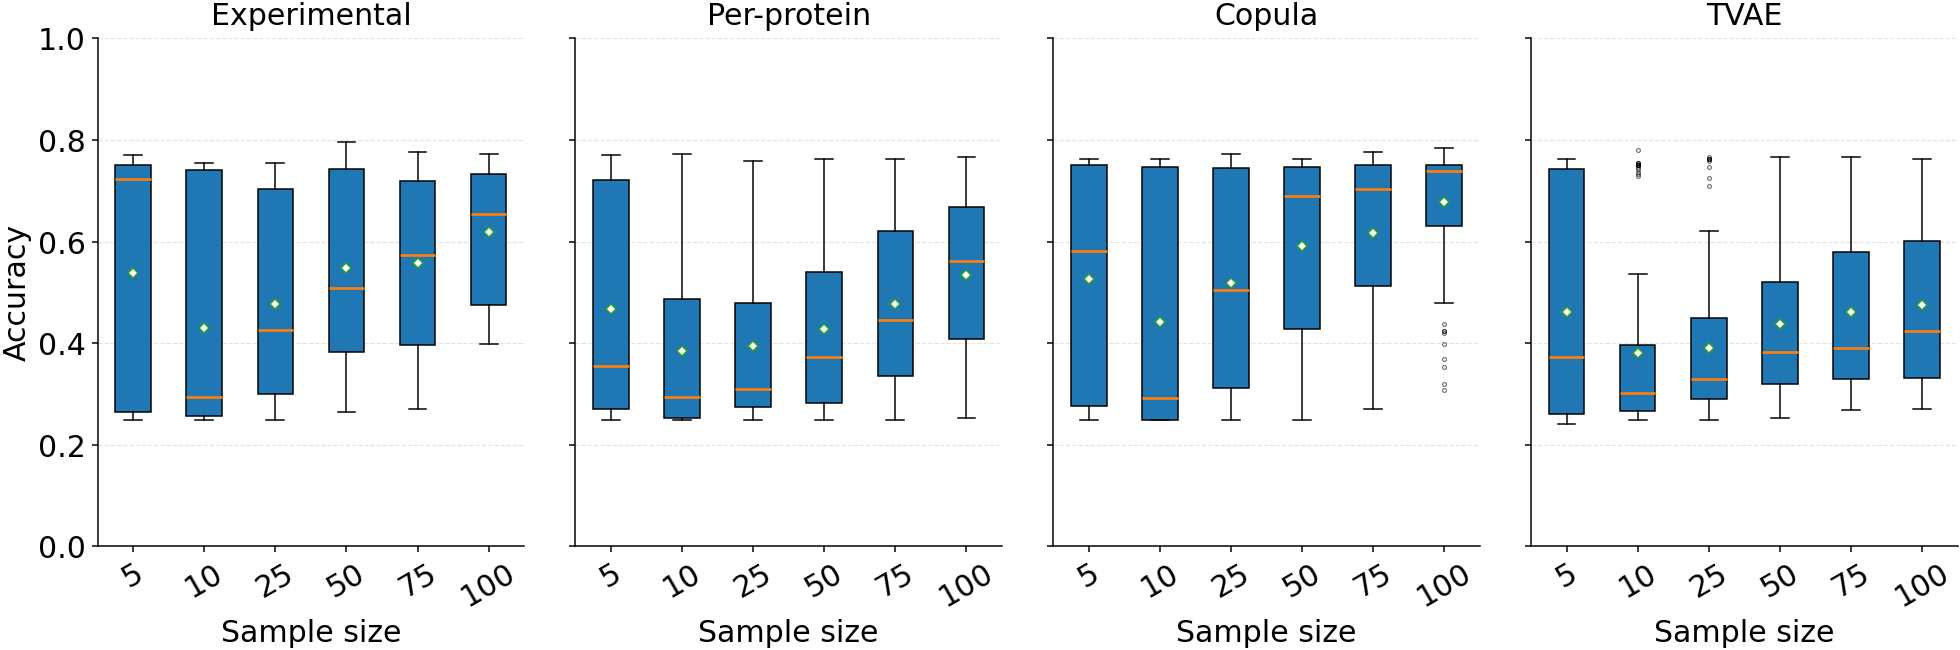

In [5]:
import matplotlib.pyplot as plt

def publication_boxpanel(
    dfs,
    titles,
    *,
    xlabel="Sample size",
    ylabel="Accuracy",
    ylim=(0, 1),
    figsize=(20, 5.5),
    rotation=30,
    show_mean=True,
    savepath=None,   # e.g., "accuracy_panels.pdf" or "accuracy_panels.png"
    dpi=600,
):
    """
    Publication-style multi-panel boxplot figure.

    Parameters
    ----------
    dfs : list of pandas.DataFrame
        Each df should have columns corresponding to sample sizes (or categories).
        Values are accuracies.
    titles : list of str
        Panel titles, same length as dfs.
    savepath : str or None
        If given, figure is saved (PDF/SVG recommended). Otherwise just shown.
    """

    # --- Global typography / rcParams (minimal, journal-friendly) ---
    plt.rcParams.update({
        "font.size": 18,
        "axes.titlesize": 18,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "axes.linewidth": 0.9,
        "xtick.major.width": 0.9,
        "ytick.major.width": 0.9,
        "xtick.major.size": 3.5,
        "ytick.major.size": 3.5,
        "figure.dpi": 120,
        "savefig.dpi": dpi,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.02,
    })

    n = len(dfs)
    fig, axes = plt.subplots(
        1, n, figsize=figsize, sharey=True,
        gridspec_kw={"wspace": 0.12}
    )
    if n == 1:
        axes = [axes]

    for i, (df, title, ax) in enumerate(zip(dfs, titles, axes)):
        # Ensure deterministic column order
        cols = list(df.columns)

        ax.boxplot(
            [df[c].dropna().values for c in cols],
            labels=[str(c) for c in cols],
            patch_artist=True,
            showmeans=show_mean,
            meanprops=dict(marker="D", markersize=4, markerfacecolor="white",
                           markeredgewidth=0.9),
            medianprops=dict(linewidth=1.6),
            boxprops=dict(linewidth=0.9),
            whiskerprops=dict(linewidth=0.9),
            capprops=dict(linewidth=0.9),
            flierprops=dict(marker="o", markersize=2.3, markerfacecolor="none",
                            markeredgewidth=0.7, alpha=0.55),
        )

        # Style: white boxes + subtle outlines (prints well)
        for b in ax.artists:
            b.set_facecolor("white")
            b.set_edgecolor("black")

        ax.set_title(title, pad=8)
        ax.set_xlabel(xlabel)
        ax.set_ylim(*ylim)

        # Light y-grid only
        ax.grid(True, axis="y", linestyle="--", linewidth=0.7, alpha=0.35)
        ax.grid(False, axis="x")

        # Rotate tick labels gently (avoid 45 unless needed)
        ax.tick_params(axis="x", rotation=rotation)

        # Clean spines
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # Only left panel gets y-label
        if i == 0:
            ax.set_ylabel(ylabel)

    fig.align_ylabels(axes)

    if savepath:
        fig.savefig(savepath)
    plt.show()


# --- Usage (replace with your existing objects) ---
publication_boxpanel(
    dfs=[
        experimental_model_accuracy,
        pprotein_model_accuracy,
        copula_model_accuracy,
        tvae_model_accuracy,
    ],
    titles=[
        "Experimental",
        "Per-protein",
        "Copula",
        "TVAE"
    ],
    savepath=None,  # e.g. "accuracy_panels.pdf"
)

## PCA Variance Explained

### Experimental

In [13]:
experimental_pca_var = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        training_data = experimental_input[i][s]

        temp_acc.append(get_pca_explained_variance(training_data.drop(columns=["Condition"]), 5)["total_variance"])
    experimental_pca_var[i] = temp_acc
experimental_pca_var = pd.DataFrame(experimental_pca_var)

Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 5: 100%|██████████| 100/100 [00:00<00:00, 1040.59it/s]

Running simulations: 10:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 10: 100%|██████████| 100/100 [00:00<00:00, 1042.71it/s]

Running simulations: 25:   0%|          | 0/100 [00:00<?, ?it/s]

...

Running simulations: 100:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 100:  22%|██▏       | 22/100 [00:00<00:00, 216.66it/s]

Running simulations: 100:  54%|█████▍    | 54/100 [00:00<00:00, 276.13it/s]

Running simulations: 100:  89%|████████▉ | 89/100 [00:00<00:00, 304.90it/s]

Running simulations: 100: 100%|██████████| 100/100 [00:00<00:00, 294.64it/s]

### Copula

In [14]:
copula_pca_var = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        copula_data = copula_input[i][s]
        try:
            temp_acc.append(get_pca_explained_variance(copula_data.drop(columns=["Condition"]), 5)["total_variance"])
        except:
            temp_acc.append(np.nan)
    copula_pca_var[i] = temp_acc
copula_pca_var = pd.DataFrame(copula_pca_var)

Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 5:  84%|████████▍ | 84/100 [00:00<00:00, 835.21it/s]

Running simulations: 5: 100%|██████████| 100/100 [00:00<00:00, 844.09it/s]

Running simulations: 10:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 10: 100%|██████████| 100/100 [00:00<00:00, 993.77it/s]

...

Running simulations: 75: 100%|██████████| 100/100 [00:00<00:00, 407.69it/s]

Running simulations: 100:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 100:  38%|███▊      | 38/100 [00:00<00:00, 372.50it/s]

Running simulations: 100:  76%|███████▌  | 76/100 [00:00<00:00, 320.57it/s]

Running simulations: 100: 100%|██████████| 100/100 [00:00<00:00, 340.87it/s]

### TVAE

In [15]:
tvae_pca_var = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        tvae_data = tvae_input[i][s]
        try:
            temp_acc.append(get_pca_explained_variance(tvae_data.drop(columns=["Condition"]), 5)["total_variance"])
        except:
            temp_acc.append(np.nan)
    tvae_pca_var[i] = temp_acc
tvae_pca_var = pd.DataFrame(tvae_pca_var)

Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 5:  17%|█▋        | 17/100 [00:00<00:00, 167.10it/s]

Running simulations: 5:  41%|████      | 41/100 [00:00<00:00, 209.30it/s]

Running simulations: 5:  66%|██████▌   | 66/100 [00:00<00:00, 226.25it/s]

Running simulations: 5:  89%|████████▉ | 89/100 [00:00<00:00, 227.44it/s]

...

Running simulations: 100:  53%|█████▎    | 53/100 [00:00<00:00, 108.16it/s]

Running simulations: 100:  66%|██████▌   | 66/100 [00:00<00:00, 114.89it/s]

Running simulations: 100:  79%|███████▉  | 79/100 [00:00<00:00, 119.09it/s]

Running simulations: 100:  92%|█████████▏| 92/100 [00:00<00:00, 120.31it/s]

Running simulations: 100: 100%|██████████| 100/100 [00:00<00:00, 111.86it/s]

### Per-protein

In [16]:
pprotein_pca_var = dict()

for i in n_samples:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        pprotein_data = pprotein_input[i][s]
        try:
            temp_acc.append(get_pca_explained_variance(pprotein_data.drop(columns=["Condition"]), 5)["total_variance"])
        except:
            temp_acc.append(np.nan)
    pprotein_pca_var[i] = temp_acc
pprotein_pca_var = pd.DataFrame(pprotein_pca_var)

Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 5:  19%|█▉        | 19/100 [00:00<00:00, 187.47it/s]

Running simulations: 5:  38%|███▊      | 38/100 [00:00<00:00, 181.45it/s]

Running simulations: 5:  61%|██████    | 61/100 [00:00<00:00, 202.88it/s]

Running simulations: 5:  83%|████████▎ | 83/100 [00:00<00:00, 209.47it/s]

...

Running simulations: 100:  81%|████████  | 81/100 [00:01<00:00, 48.78it/s]

Running simulations: 100:  86%|████████▌ | 86/100 [00:01<00:00, 46.58it/s]

Running simulations: 100:  93%|█████████▎| 93/100 [00:02<00:00, 50.97it/s]

Running simulations: 100:  99%|█████████▉| 99/100 [00:02<00:00, 50.09it/s]

Running simulations: 100: 100%|██████████| 100/100 [00:02<00:00, 46.19it/s]

In [17]:
# PCA results for the combined paper figure (simulation_comparison.ipynb)
for name, df in {"experimental": experimental_pca_var, "pprotein": pprotein_pca_var,
                 "copula": copula_pca_var, "tvae": tvae_pca_var}.items():
    df.to_csv(f"../data/results/CRC/{name}_pca_var.csv")

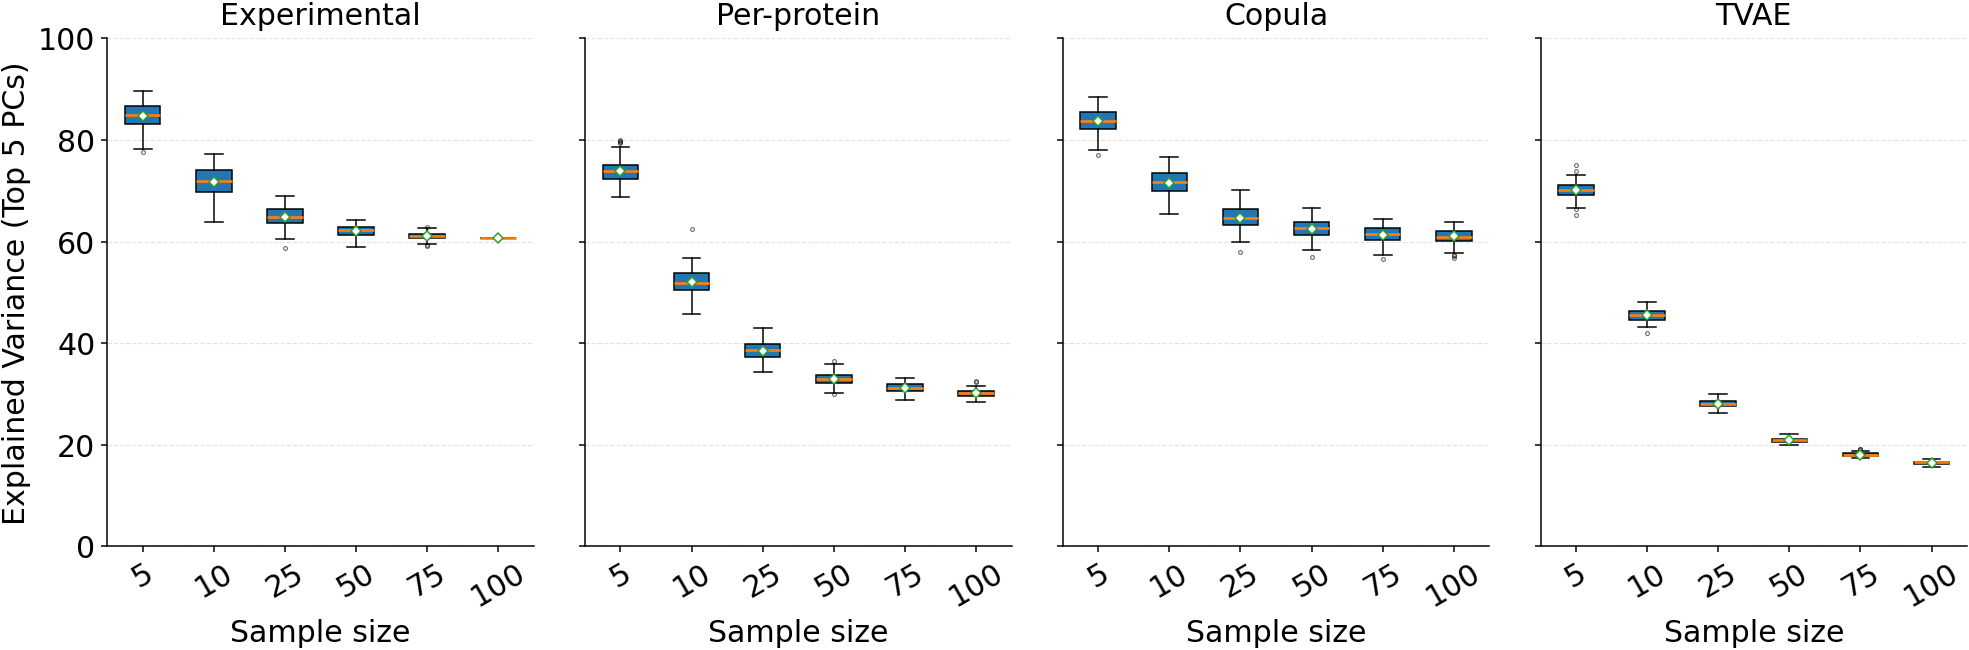

In [171]:
import matplotlib.pyplot as plt

def publication_boxpanel(
    dfs,
    titles,
    *,
    xlabel="Sample size",
    ylabel="Accuracy",
    ylim=(0, 1),
    figsize=(20, 5.5),
    rotation=30,
    show_mean=True,
    savepath=None,   # e.g., "accuracy_panels.pdf" or "accuracy_panels.png"
    dpi=600,
):
    """
    Publication-style multi-panel boxplot figure.

    Parameters
    ----------
    dfs : list of pandas.DataFrame
        Each df should have columns corresponding to sample sizes (or categories).
        Values are accuracies.
    titles : list of str
        Panel titles, same length as dfs.
    savepath : str or None
        If given, figure is saved (PDF/SVG recommended). Otherwise just shown.
    """

    # --- Global typography / rcParams (minimal, journal-friendly) ---
    plt.rcParams.update({
        "font.size": 18,
        "axes.titlesize": 18,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "axes.linewidth": 0.9,
        "xtick.major.width": 0.9,
        "ytick.major.width": 0.9,
        "xtick.major.size": 3.5,
        "ytick.major.size": 3.5,
        "figure.dpi": 120,
        "savefig.dpi": dpi,
        "savefig.bbox": "tight",
        "savefig.pad_inches": 0.02,
    })

    n = len(dfs)
    fig, axes = plt.subplots(
        1, n, figsize=figsize, sharey=True,
        gridspec_kw={"wspace": 0.12}
    )
    if n == 1:
        axes = [axes]

    for i, (df, title, ax) in enumerate(zip(dfs, titles, axes)):
        # Ensure deterministic column order
        cols = list(df.columns)

        ax.boxplot(
            [df[c].dropna().values for c in cols],
            labels=[str(c) for c in cols],
            patch_artist=True,
            showmeans=show_mean,
            meanprops=dict(marker="D", markersize=4, markerfacecolor="white",
                           markeredgewidth=0.9),
            medianprops=dict(linewidth=1.6),
            boxprops=dict(linewidth=0.9),
            whiskerprops=dict(linewidth=0.9),
            capprops=dict(linewidth=0.9),
            flierprops=dict(marker="o", markersize=2.3, markerfacecolor="none",
                            markeredgewidth=0.7, alpha=0.55),
        )

        # Style: white boxes + subtle outlines (prints well)
        for b in ax.artists:
            b.set_facecolor("white")
            b.set_edgecolor("black")

        ax.set_title(title, pad=8)
        ax.set_xlabel(xlabel)
        ax.set_ylim(*ylim)

        # Light y-grid only
        ax.grid(True, axis="y", linestyle="--", linewidth=0.7, alpha=0.35)
        ax.grid(False, axis="x")

        # Rotate tick labels gently (avoid 45 unless needed)
        ax.tick_params(axis="x", rotation=rotation)

        # Clean spines
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        # Only left panel gets y-label
        if i == 0:
            ax.set_ylabel(ylabel)

    fig.align_ylabels(axes)

    if savepath:
        fig.savefig(savepath)
    plt.show()


# --- Usage (replace with your existing objects) ---
publication_boxpanel(
    dfs=[
        experimental_pca_var,
        tvae_pca_var,
        copula_pca_var,
        pprotein_pca_var,
    ],
    titles=[
        "Experimental",
        "Per-protein",
        "Copula",
        "TVAE"
    ],
    savepath=None,  # e.g. "accuracy_panels.pdf"
    xlabel="Sample size",
    ylabel="Explained Variance (Top 5 PCs)",
    ylim=(0, 100),
)

## $t$-test Power Calcuation

### Calculate experimental "positives"

In [8]:
from MSquantSim.downstreamanalysis import run_ttest

# Ground-truth "positives": proteins called significant on the full experimental arms.
# assign() rather than in-place assignment so the simulation inputs above keep their
# original columns if these cells are re-run.
crc_experimental_all = pd.concat([
    crc_healthy.assign(Condition="Control"),
    crc_disease.assign(Condition="CRC"),
], axis=0)

da_results = run_ttest(
    crc_experimental_all, condition_col='Condition', equal_var=False,
    adjust_pvalues=True, significance_level=0.1, min_samples=2,
    sort_by_pvalue=True)

positives = da_results.loc[da_results["significant"] == True]["Protein"].values
print(f"{len(positives)} significant proteins out of {len(da_results)} tested")

7 significant proteins out of 67 tested


In [173]:
positives

array(['TIMP1', 'MMRN1', 'LRG1', 'HP', 'ORM1', 'CTSD', 'CP'], dtype=object)

### Experimental

In [19]:
experimental_positive_counts = dict()
experimental_valid_iterations = dict()
experimental_diffs = list()

for i in n_samples:
    counts = pd.Series(0, index=positives)
    n_valid = 0
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        training_data = crc_validation_input.sample(n=i*2, random_state=s)
        try:
            da_results = run_ttest(training_data)
        except ValueError:
            # Subsample landed on a single condition, so no test is possible
            continue
        n_valid += 1
        sig_proteins = da_results.loc[da_results["significant"] == True, "Protein"]
        counts += counts.index.isin(sig_proteins)
        # Keep every protein's effect size so diffs can be pooled across n and s
        experimental_diffs.append(
            da_results[["Protein", "diff"]].assign(n_samples=i, iteration=s)
        )
    experimental_positive_counts[i] = counts
    experimental_valid_iterations[i] = n_valid

experimental_positive_counts = pd.DataFrame(experimental_positive_counts)
experimental_positive_counts.index.name = "Protein"
experimental_positive_counts = experimental_positive_counts.reset_index()

experimental_diffs = pd.concat(experimental_diffs, ignore_index=True)

print("Iterations with both conditions present:", experimental_valid_iterations)

Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 5:   2%|▏         | 2/100 [00:00<00:05, 18.20it/s]

Running simulations: 5:   4%|▍         | 4/100 [00:00<00:06, 15.30it/s]

Running simulations: 5:   8%|▊         | 8/100 [00:00<00:03, 23.76it/s]

Running simulations: 5:  11%|█         | 11/100 [00:00<00:04, 18.35it/s]

...

Running simulations: 100:  94%|█████████▍| 94/100 [00:05<00:00, 11.45it/s]

Running simulations: 100:  96%|█████████▌| 96/100 [00:05<00:00, 12.37it/s]

Running simulations: 100:  99%|█████████▉| 99/100 [00:05<00:00, 14.95it/s]

Running simulations: 100: 100%|██████████| 100/100 [00:05<00:00, 18.24it/s]

Iterations with both conditions present: {5: 96, 10: 99, 25: 100, 50: 100, 75: 100, 100: 100}


In [20]:
experimental_dd_positive_counts = dict()
experimental_dd_valid_iterations = dict()
experimental_dd_diffs = list()

for i in n_samples:
    counts = pd.Series(0, index=positives)
    n_valid = 0
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        training_data = experimental_input[i][s]
        try:
            da_results = run_ttest(training_data)
        except ValueError:
            # Subsample landed on a single condition, so no test is possible
            continue
        n_valid += 1
        sig_proteins = da_results.loc[da_results["significant"] == True, "Protein"]
        counts += counts.index.isin(sig_proteins)
        # Keep every protein's effect size so diffs can be pooled across n and s
        experimental_dd_diffs.append(
            da_results[["Protein", "diff"]].assign(n_samples=i, iteration=s)
        )
    experimental_dd_positive_counts[i] = counts
    experimental_dd_valid_iterations[i] = n_valid

experimental_dd_positive_counts = pd.DataFrame(experimental_dd_positive_counts)
experimental_dd_positive_counts.index.name = "Protein"
experimental_dd_positive_counts = experimental_dd_positive_counts.reset_index()

experimental_dd_diffs = pd.concat(experimental_dd_diffs, ignore_index=True)

print("Iterations with both conditions present:", experimental_dd_valid_iterations)

Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 5:   2%|▏         | 2/100 [00:00<00:06, 14.72it/s]

Running simulations: 5:   4%|▍         | 4/100 [00:00<00:05, 16.49it/s]

Running simulations: 5:   8%|▊         | 8/100 [00:00<00:03, 23.07it/s]

Running simulations: 5:  11%|█         | 11/100 [00:00<00:04, 22.12it/s]

...

Running simulations: 100:  93%|█████████▎| 93/100 [00:04<00:00, 17.55it/s]

Running simulations: 100:  96%|█████████▌| 96/100 [00:04<00:00, 17.79it/s]

Running simulations: 100:  99%|█████████▉| 99/100 [00:04<00:00, 20.09it/s]

Running simulations: 100: 100%|██████████| 100/100 [00:04<00:00, 20.68it/s]

Iterations with both conditions present: {5: 100, 10: 100, 25: 100, 50: 100, 75: 100, 100: 100}


### Copula

In [21]:
copula_positive_counts = dict()
copula_valid_iterations = dict()
copula_diffs = list()

for i in n_samples:
    counts = pd.Series(0, index=positives)
    n_valid = 0
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        copula_data = copula_input[i][s]
        try:
            da_results = run_ttest(copula_data)
        except ValueError:
            # Simulation landed on a single condition, so no test is possible
            continue
        n_valid += 1
        sig_proteins = da_results.loc[da_results["significant"] == True, "Protein"]
        counts += counts.index.isin(sig_proteins)
        # Keep every protein's effect size so diffs can be pooled across n and s
        copula_diffs.append(
            da_results[["Protein", "diff"]].assign(n_samples=i, iteration=s)
        )
    copula_positive_counts[i] = counts
    copula_valid_iterations[i] = n_valid

copula_positive_counts = pd.DataFrame(copula_positive_counts)
copula_positive_counts.index.name = "Protein"
copula_positive_counts = copula_positive_counts.reset_index()

copula_diffs = pd.concat(copula_diffs, ignore_index=True)

print("Iterations with both conditions present:", copula_valid_iterations)

Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 5:   2%|▏         | 2/100 [00:00<00:07, 13.68it/s]

Running simulations: 5:   4%|▍         | 4/100 [00:00<00:08, 11.59it/s]

Running simulations: 5:   6%|▌         | 6/100 [00:00<00:08, 11.38it/s]

Running simulations: 5:   8%|▊         | 8/100 [00:00<00:08, 11.30it/s]

...

Running simulations: 100:  89%|████████▉ | 89/100 [00:03<00:00, 15.29it/s]

Running simulations: 100:  94%|█████████▍| 94/100 [00:03<00:00, 19.89it/s]

Running simulations: 100:  99%|█████████▉| 99/100 [00:03<00:00, 24.45it/s]

Running simulations: 100: 100%|██████████| 100/100 [00:03<00:00, 25.53it/s]

Iterations with both conditions present: {5: 100, 10: 100, 25: 100, 50: 100, 75: 100, 100: 100}


### TVAE

In [22]:
tvae_positive_counts = dict()
tvae_valid_iterations = dict()
tvae_diffs = list()

for i in n_samples:
    counts = pd.Series(0, index=positives)
    n_valid = 0
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        tvae_data = tvae_input[i][s]
        try:
            da_results = run_ttest(tvae_data)
        except ValueError:
            # Simulation landed on a single condition, so no test is possible
            continue
        n_valid += 1
        sig_proteins = da_results.loc[da_results["significant"] == True, "Protein"]
        counts += counts.index.isin(sig_proteins)
        # Keep every protein's effect size so diffs can be pooled across n and s
        tvae_diffs.append(
            da_results[["Protein", "diff"]].assign(n_samples=i, iteration=s)
        )
    tvae_positive_counts[i] = counts
    tvae_valid_iterations[i] = n_valid

tvae_positive_counts = pd.DataFrame(tvae_positive_counts)
tvae_positive_counts.index.name = "Protein"
tvae_positive_counts = tvae_positive_counts.reset_index()

tvae_diffs = pd.concat(tvae_diffs, ignore_index=True)

print("Iterations with both conditions present:", tvae_valid_iterations)

Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 5:   4%|▍         | 4/100 [00:00<00:02, 34.14it/s]

Running simulations: 5:   8%|▊         | 8/100 [00:00<00:02, 36.61it/s]

Running simulations: 5:  12%|█▏        | 12/100 [00:00<00:02, 37.91it/s]

Running simulations: 5:  17%|█▋        | 17/100 [00:00<00:02, 39.48it/s]

...

Running simulations: 100:  88%|████████▊ | 88/100 [00:02<00:00, 37.79it/s]

Running simulations: 100:  93%|█████████▎| 93/100 [00:02<00:00, 39.39it/s]

Running simulations: 100:  98%|█████████▊| 98/100 [00:02<00:00, 40.12it/s]

Running simulations: 100: 100%|██████████| 100/100 [00:02<00:00, 39.71it/s]

Iterations with both conditions present: {5: 100, 10: 100, 25: 100, 50: 100, 75: 100, 100: 100}


### Per-protein

In [23]:
pprotein_positive_counts = dict()
pprotein_valid_iterations = dict()
pprotein_diffs = list()

for i in n_samples:
    counts = pd.Series(0, index=positives)
    n_valid = 0
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        pprotein_data = pprotein_input[i][s]
        try:
            da_results = run_ttest(pprotein_data)
        except ValueError:
            # Simulation landed on a single condition, so no test is possible
            continue
        n_valid += 1
        sig_proteins = da_results.loc[da_results["significant"] == True, "Protein"]
        counts += counts.index.isin(sig_proteins)
        # Keep every protein's effect size so diffs can be pooled across n and s
        pprotein_diffs.append(
            da_results[["Protein", "diff"]].assign(n_samples=i, iteration=s)
        )
    pprotein_positive_counts[i] = counts
    pprotein_valid_iterations[i] = n_valid

pprotein_positive_counts = pd.DataFrame(pprotein_positive_counts)
pprotein_positive_counts.index.name = "Protein"
pprotein_positive_counts = pprotein_positive_counts.reset_index()

pprotein_diffs = pd.concat(pprotein_diffs, ignore_index=True)

print("Iterations with both conditions present:", pprotein_valid_iterations)

Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 5:   5%|▌         | 5/100 [00:00<00:02, 41.86it/s]

Running simulations: 5:  10%|█         | 10/100 [00:00<00:02, 34.03it/s]

Running simulations: 5:  14%|█▍        | 14/100 [00:00<00:02, 34.41it/s]

Running simulations: 5:  18%|█▊        | 18/100 [00:00<00:02, 32.58it/s]

...

Running simulations: 100:  86%|████████▌ | 86/100 [00:02<00:00, 39.91it/s]

Running simulations: 100:  91%|█████████ | 91/100 [00:02<00:00, 41.41it/s]

Running simulations: 100:  96%|█████████▌| 96/100 [00:02<00:00, 41.29it/s]

Running simulations: 100: 100%|██████████| 100/100 [00:02<00:00, 40.53it/s]

Iterations with both conditions present: {5: 100, 10: 100, 25: 100, 50: 100, 75: 100, 100: 100}


In [24]:
# t-test power results for the combined paper figure (simulation_comparison.ipynb).
# Counts: number of valid iterations in which each experimentally significant protein
# was detected. "experimental" subsamples the validation set; "experimental_train"
# subsamples the training set.
power_results = {
    "experimental": (experimental_positive_counts, experimental_valid_iterations),
    "experimental_train": (experimental_dd_positive_counts, experimental_dd_valid_iterations),
    "pprotein": (pprotein_positive_counts, pprotein_valid_iterations),
    "copula": (copula_positive_counts, copula_valid_iterations),
    "tvae": (tvae_positive_counts, tvae_valid_iterations),
}
for name, (counts, valid) in power_results.items():
    counts.to_csv(f"../data/results/CRC/{name}_power_counts.csv", index=False)
    (pd.Series(valid, name="n_valid").rename_axis("n_samples")
       .to_csv(f"../data/results/CRC/{name}_power_valid.csv"))

### Compare

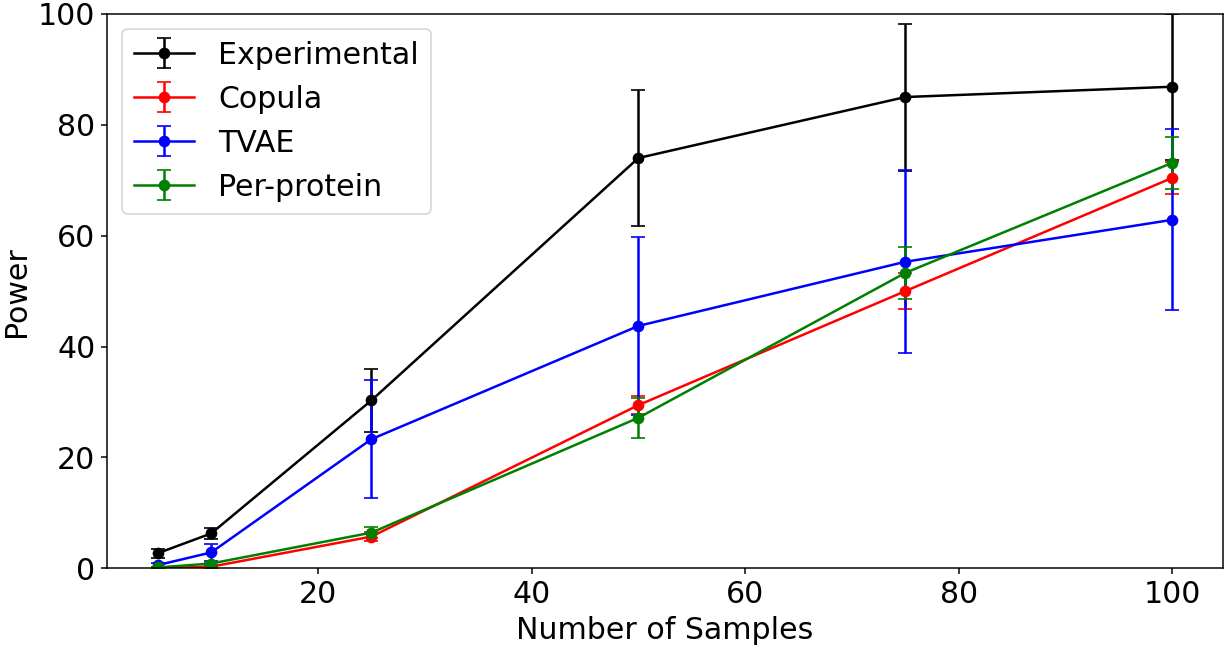

In [176]:
fig, ax = plt.subplots(figsize=(12, 6))

# Error bars show the standard error of the mean across the "positive" proteins
ax.errorbar(n_samples, 
            experimental_positive_counts.iloc[:,1:].mean(axis=0).values, 
            yerr=experimental_positive_counts.iloc[:,1:].sem(axis=0).values, 
            marker='o', capsize=4, label='Experimental', color='black')

ax.errorbar(n_samples, 
            copula_positive_counts.iloc[:,1:].mean(axis=0).values, 
            yerr=copula_positive_counts.iloc[:,1:].sem(axis=0).values, 
            marker='o', capsize=4, label='Copula', color='red')

ax.errorbar(n_samples, 
            tvae_positive_counts.iloc[:,1:].mean(axis=0).values, 
            yerr=tvae_positive_counts.iloc[:,1:].sem(axis=0).values, 
            marker='o', capsize=4, label='TVAE', color='blue')

ax.errorbar(n_samples, 
            pprotein_positive_counts.iloc[:,1:].mean(axis=0).values, 
            yerr=pprotein_positive_counts.iloc[:,1:].sem(axis=0).values, 
            marker='o', capsize=4, label='Per-protein', color='green')
ax.set_ylim(0, 100)
ax.set_xlabel('Number of Samples')
ax.set_ylabel('Power')
ax.legend()

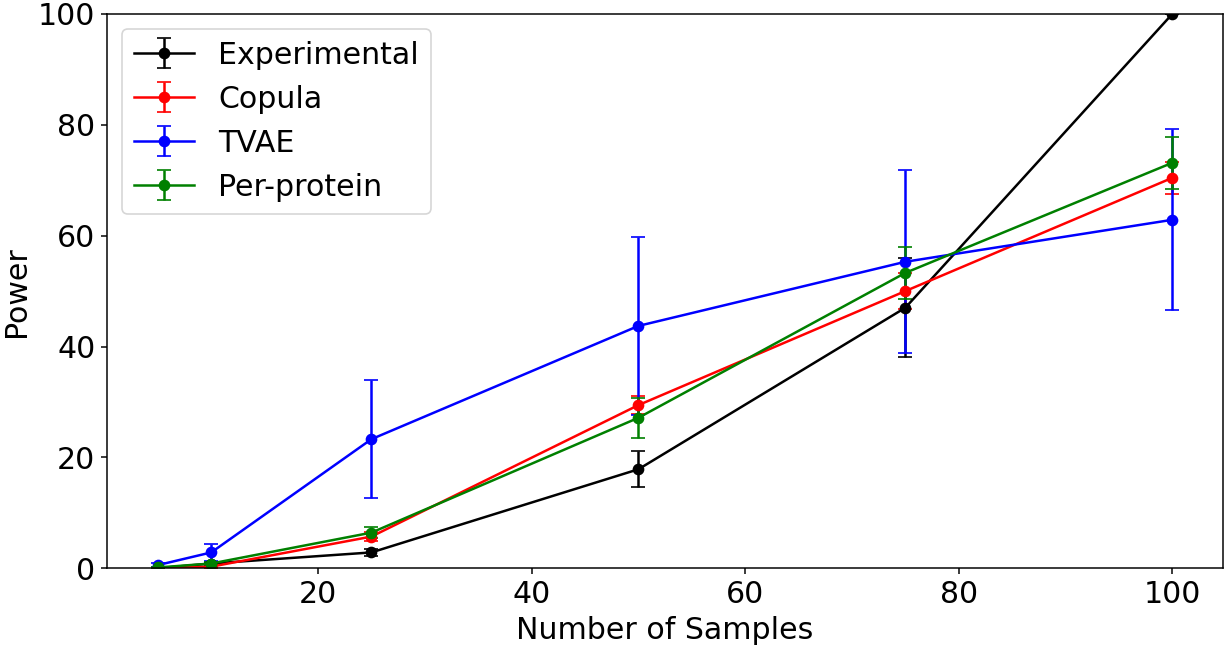

In [178]:
fig, ax = plt.subplots(figsize=(12, 6))

# Error bars show the standard error of the mean across the "positive" proteins
ax.errorbar(n_samples, 
            experimental_dd_positive_counts.iloc[:,1:].mean(axis=0).values, 
            yerr=experimental_dd_positive_counts.iloc[:,1:].sem(axis=0).values, 
            marker='o', capsize=4, label='Experimental', color='black')

ax.errorbar(n_samples, 
            copula_positive_counts.iloc[:,1:].mean(axis=0).values, 
            yerr=copula_positive_counts.iloc[:,1:].sem(axis=0).values, 
            marker='o', capsize=4, label='Copula', color='red')

ax.errorbar(n_samples, 
            tvae_positive_counts.iloc[:,1:].mean(axis=0).values, 
            yerr=tvae_positive_counts.iloc[:,1:].sem(axis=0).values, 
            marker='o', capsize=4, label='TVAE', color='blue')

ax.errorbar(n_samples, 
            pprotein_positive_counts.iloc[:,1:].mean(axis=0).values, 
            yerr=pprotein_positive_counts.iloc[:,1:].sem(axis=0).values, 
            marker='o', capsize=4, label='Per-protein', color='green')
ax.set_ylim(0, 100)
ax.set_xlabel('Number of Samples')
ax.set_ylabel('Power')
ax.legend()

## Fine-grid Copula analyses for the sample-size table

Copula-only RF accuracy, PCA variance and $t$-test power on a finer grid of sample sizes; these results feed the Step 4 sample-size table in `simulation_comparison.ipynb`.

In [9]:
fine_n = [5, 10, 15, 20, 25, 30, 40, 50, 60, 70, 80, 90, 100]

# Same construction as the copula_input cell above, on the finer grid of sample sizes.
# random_state=s is passed to .sample() so these subsamples (and every result below)
# are reproducible.
copula_input_fine = {}

for i in fine_n:
    temp_list = list()
    for s in range(100):
        copula_healthy_results = copula_sim_crc_healthy_multi[s].sample(n=i, random_state=s)
        copula_disease_results = copula_sim_crc_disease_multi[s].sample(n=i, random_state=s)

        copula_healthy_results.loc[:, "Condition"] = "Control"
        copula_disease_results.loc[:, "Condition"] = "CRC"

        temp_list.append(pd.concat([copula_healthy_results,
                                    copula_disease_results], axis=0))

    copula_input_fine[i] = temp_list

In [10]:
# PCA variance explained by the top 5 components (same as the Copula PCA cell above)
copula_pca_var_fine = dict()

for i in fine_n:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        copula_data = copula_input_fine[i][s]
        try:
            temp_acc.append(get_pca_explained_variance(copula_data.drop(columns=["Condition"]), 5)["total_variance"])
        except:
            temp_acc.append(np.nan)
    copula_pca_var_fine[i] = temp_acc
copula_pca_var_fine = pd.DataFrame(copula_pca_var_fine)

copula_pca_var_fine.to_csv("../data/results/CRC/copula_pca_var_fine.csv")

Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 5:  94%|█████████▍| 94/100 [00:00<00:00, 934.01it/s]

Running simulations: 5: 100%|██████████| 100/100 [00:00<00:00, 924.24it/s]

Running simulations: 10:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 10:  99%|█████████▉| 99/100 [00:00<00:00, 983.74it/s]

...

Running simulations: 90: 100%|██████████| 100/100 [00:00<00:00, 399.90it/s]

Running simulations: 100:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 100:  39%|███▉      | 39/100 [00:00<00:00, 388.97it/s]

Running simulations: 100:  82%|████████▏ | 82/100 [00:00<00:00, 412.28it/s]

Running simulations: 100: 100%|██████████| 100/100 [00:00<00:00, 400.47it/s]

In [11]:
# t-test power (same logic as the Copula power cell above): for each n, count the valid
# iterations in which each experimentally significant protein ("positives") is detected.
copula_positive_counts_fine = dict()
copula_valid_iterations_fine = dict()

for i in fine_n:
    counts = pd.Series(0, index=positives)
    n_valid = 0
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        copula_data = copula_input_fine[i][s]
        try:
            da_results_fine = run_ttest(copula_data)
        except ValueError:
            # Simulation landed on a single condition, so no test is possible
            continue
        n_valid += 1
        sig_proteins = da_results_fine.loc[da_results_fine["significant"] == True, "Protein"]
        counts += counts.index.isin(sig_proteins)
    copula_positive_counts_fine[i] = counts
    copula_valid_iterations_fine[i] = n_valid

copula_positive_counts_fine = pd.DataFrame(copula_positive_counts_fine)
copula_positive_counts_fine.index.name = "Protein"
copula_positive_counts_fine = copula_positive_counts_fine.reset_index()

print("Iterations with both conditions present:", copula_valid_iterations_fine)

# Same format as the existing *_power_counts.csv / *_power_valid.csv files
copula_positive_counts_fine.to_csv("../data/results/CRC/copula_power_counts_fine.csv", index=False)
(pd.Series(copula_valid_iterations_fine, name="n_valid").rename_axis("n_samples")
   .to_csv("../data/results/CRC/copula_power_valid_fine.csv"))

Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 5:   4%|▍         | 4/100 [00:00<00:02, 37.08it/s]

Running simulations: 5:   9%|▉         | 9/100 [00:00<00:02, 40.45it/s]

Running simulations: 5:  14%|█▍        | 14/100 [00:00<00:02, 40.21it/s]

Running simulations: 5:  19%|█▉        | 19/100 [00:00<00:01, 41.40it/s]

...

Running simulations: 100:  87%|████████▋ | 87/100 [00:01<00:00, 46.22it/s]

Running simulations: 100:  92%|█████████▏| 92/100 [00:01<00:00, 44.77it/s]

Running simulations: 100:  97%|█████████▋| 97/100 [00:02<00:00, 45.15it/s]

Running simulations: 100: 100%|██████████| 100/100 [00:02<00:00, 46.78it/s]

Iterations with both conditions present: {5: 100, 10: 100, 15: 100, 20: 100, 25: 100, 30: 100, 40: 100, 50: 100, 60: 100, 70: 100, 80: 100, 90: 100, 100: 100}


In [12]:
# RF accuracy on the validation set (same as the Copula RF cell above)
copula_model_accuracy_fine = dict()

for i in fine_n:
    temp_acc = list()
    for s in tqdm(range(100), desc=f"Running simulations: {i}"):
        training_data = copula_input_fine[i][s]

        X = training_data.drop("Condition", axis=1)
        y = training_data["Condition"]
        temp_acc.append(train_rf(X, y, crc_validation_input))
    copula_model_accuracy_fine[i] = temp_acc
copula_model_accuracy_fine = pd.DataFrame(copula_model_accuracy_fine)

copula_model_accuracy_fine.to_csv("../data/results/CRC/copula_model_accuracy_fine.csv")

Running simulations: 5:   0%|          | 0/100 [00:00<?, ?it/s]

Running simulations: 5:   1%|          | 1/100 [00:02<04:42,  2.85s/it]

Running simulations: 5:   2%|▏         | 2/100 [00:04<03:54,  2.39s/it]

Running simulations: 5:   3%|▎         | 3/100 [00:06<03:37,  2.25s/it]

Running simulations: 5:   4%|▍         | 4/100 [00:09<03:32,  2.21s/it]

...

Running simulations: 100:  97%|█████████▋| 97/100 [06:40<00:12,  4.18s/it]

Running simulations: 100:  98%|█████████▊| 98/100 [06:44<00:08,  4.08s/it]

Running simulations: 100:  99%|█████████▉| 99/100 [06:48<00:03,  3.98s/it]

Running simulations: 100: 100%|██████████| 100/100 [06:52<00:00,  4.00s/it]

Running simulations: 100: 100%|██████████| 100/100 [06:52<00:00,  4.12s/it]

# Reserve (not used in the paper)

Older and superseded analyses, kept for reference. Nothing in the paper depends on the cells below. They were moved here unchanged on 2026-10-21 (`plans/notebook_reorder.md`); running the notebook from the top gives them the same inputs as before.

## Planning. Use simulations to plan future experiments


#### Visual Metrics

#### Pairplot Experimental data

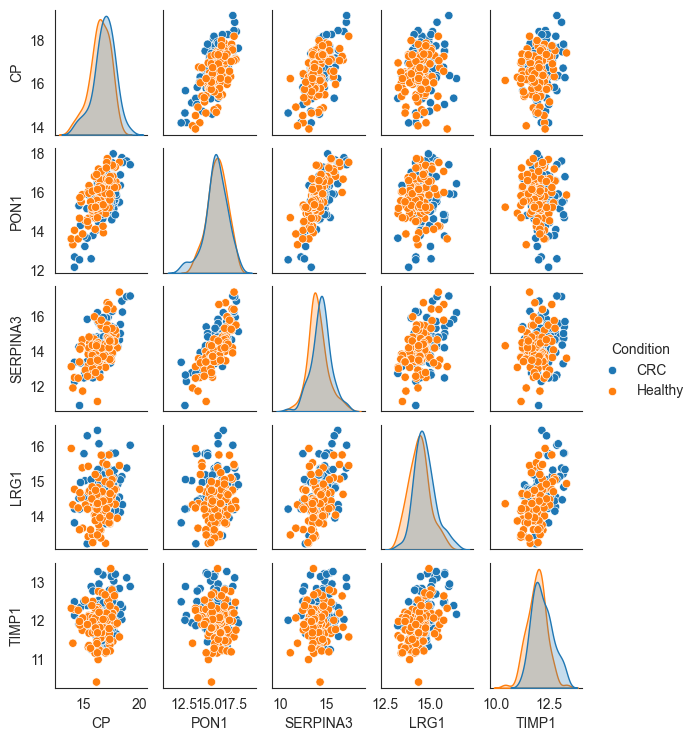

In [3]:
sns.set_style("white")
sns.pairplot(data[["CP","PON1","SERPINA3","LRG1","TIMP1","Condition"]], hue="Condition",height=1.5, aspect=0.8)

#### Pairplot Per-protein data

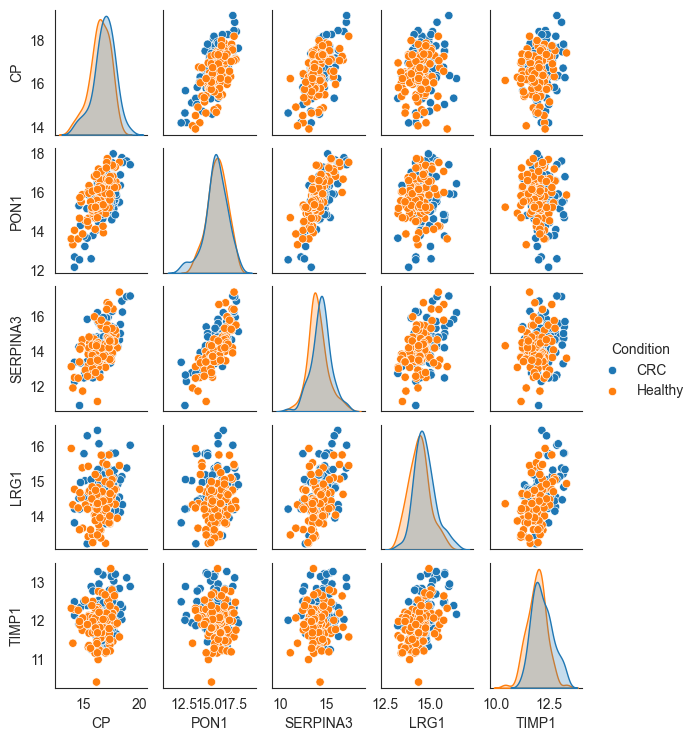

In [4]:
simpp0 = pd.read_csv('../casestudy/crc/perprotein/crc0_pp_0.csv')
simpp1 = pd.read_csv('../casestudy/crc/perprotein/crc1_pp_0.csv')
merged_df = pd.merge(simpp0, simpp1, how='outer', indicator=True)
merged_df['Condition'] = merged_df['_merge'].map({ 'left_only': 0, 'right_only': 1})
merged_df = merged_df.drop('_merge', axis=1)
sns.pairplot(data[["CP","PON1","SERPINA3","LRG1","TIMP1","Condition"]], hue="Condition",height=1.5, aspect=0.8)

#### Pairplot TVAE data

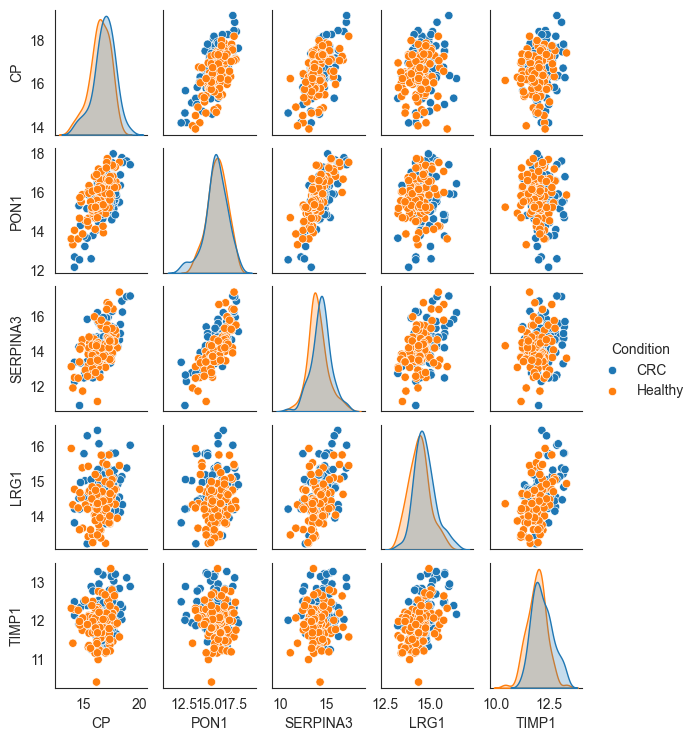

In [5]:
simtvae0 = pd.read_csv('../casestudy/crc/tvae/crc0_tvae_0.csv')
simtvae1 = pd.read_csv('../casestudy/crc/tvae/crc1_tvae_0.csv')
merged_df = pd.merge(simtvae0, simtvae1, how='outer', indicator=True)
merged_df['Condition'] = merged_df['_merge'].map({ 'left_only': 0, 'right_only': 1})
merged_df = merged_df.drop('_merge', axis=1)
sns.pairplot(data[["CP","PON1","SERPINA3","LRG1","TIMP1","Condition"]], hue="Condition",height=1.5, aspect=0.8)

#### Pairplot Copula data

In [11]:
df

,A1AG2,AFM,AHSG,ANT3,AOC3,APOB,ATRN,BTD,C20orf3,CADM1,...,PTPRJ,Q5JNX2,SERPINA1,SERPINA3,SERPINA6,SERPINA7,THBS1,TIMP1,VTN,VWF
100,14.522701,15.940212,20.084743,17.854882,9.265317,15.561483,13.277309,15.841669,11.378164,8.886986,...,9.974945,19.810557,16.734527,14.670002,15.903624,13.240460,14.429249,11.757719,12.961205,11.148027
101,15.294532,15.935520,19.784254,17.318508,9.731454,15.739329,14.558598,15.970486,10.837733,10.162198,...,10.224742,19.417183,19.055394,14.957223,16.638847,13.368402,14.804730,11.906788,12.124032,10.050453
102,14.317982,16.029300,19.826004,17.168676,10.719039,15.031820,13.823845,15.961511,10.878353,9.399227,...,9.369648,19.009737,18.014983,14.712584,15.778314,13.605648,14.881317,11.997252,11.696529,11.122208
103,14.743974,17.271903,20.546815,17.614134,10.425442,15.755704,13.894078,16.797642,12.043986,10.036943,...,10.386299,19.165669,17.274783,14.509578,16.018403,13.797991,16.307502,12.344813,13.262589,10.841750
104,14.473524,15.997162,19.822254,16.851331,9.359456,15.273471,13.823559,16.317857,11.503514,9.488784,...,10.332763,19.338430,17.778327,13.572941,15.541310,13.130568,15.023347,12.220879,12.233400,10.814681
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,14.442917,15.990122,18.665888,16.506105,9.325916,14.745428,13.072122,15.534248,10.767566,9.142328,...,10.116428,19.185454,16.173700,13.396709,14.815274,12.338600,15.691712,11.984285,11.879767,11.062184
196,15.116044,16.625768,19.475982,17.245004,9.258360,15.141649,13.424602,15.977121,9.889204,9.298522,...,10.051727,20.052715,16.286212,12.785561,15.497808,13.122072,13.001543,11.816094,12.012430,10.250246
197,15.041488,15.224106,18.525146,16.235877,9.284527,14.812296,13.922798,14.939264,10.622075,8.846313,...,9.538417,18.668108,17.149908,11.122248,15.228195,11.783661,13.346080,11.176881,12.438623,9.410451
198,13.922867,16.388432,19.199723,16.204601,9.089451,14.572485,12.838552,15.439934,9.883794,8.043888,...,9.652422,19.585959,15.788897,12.577409,14.677995,12.614804,14.596866,11.905893,10.916887,10.700179


(array([   0.,  200.,  400.,  600.,  800., 1000., 1200.]),
 [Text(0, 0.0, '0'),
  Text(0, 200.0, '200'),
  Text(0, 400.0, '400'),
  Text(0, 600.0, '600'),
  Text(0, 800.0, '800'),
  Text(0, 1000.0, '1000'),
  Text(0, 1200.0, '1200')])

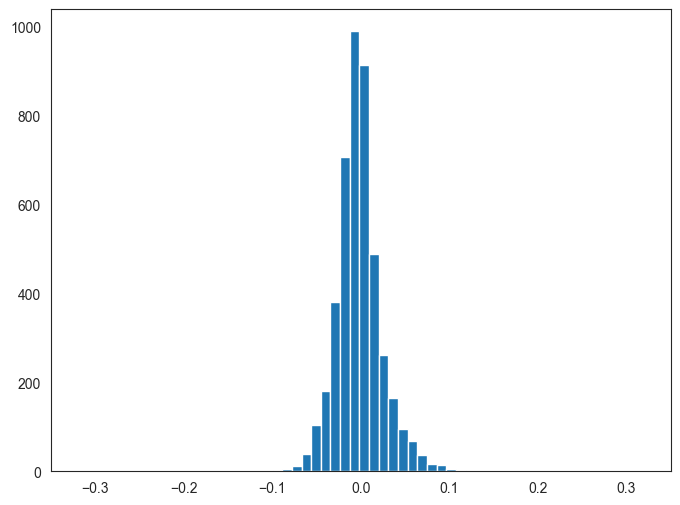

In [18]:
simco0 = pd.read_csv('../casestudy/crc/copula/test.csv')#crc0_gm_copula_0.csv')
df = data
df_with_0 = df[df['Condition'] == 'Healthy'].drop(columns='Condition')
df_with_1 = df[df['Condition'] == 'CRC'].drop(columns='Condition')
df = df_with_0

fig, ax = plt.subplots(figsize=(8,6))
ax.hist(pd.Series((df.corr() - simco0.corr()).values.flatten()), bins=20)
ax.set_xlim(-.35,.35)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

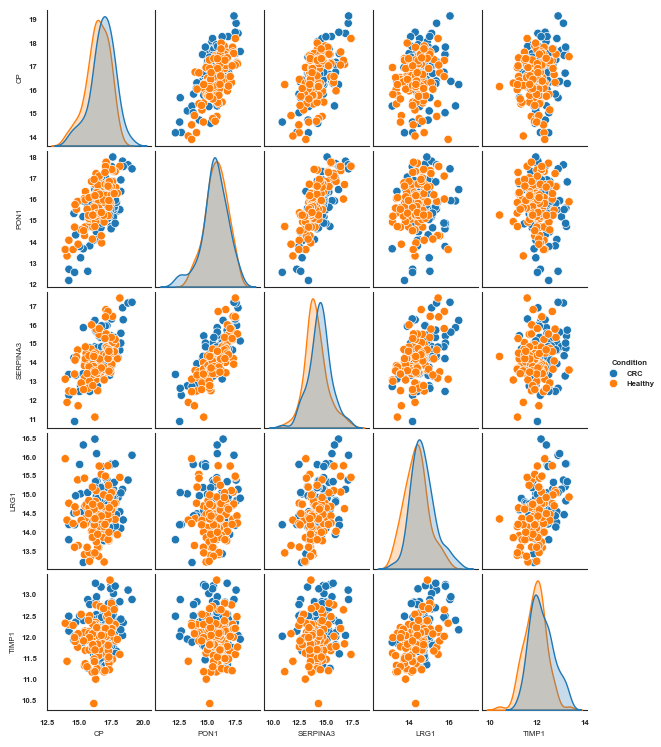

In [38]:
simco0 = pd.read_csv('../casestudy/crc/copula/test.csv')#crc0_gm_copula_0.csv')
simco1 = pd.read_csv('../casestudy/crc/copula/crc1_gm_copula_0.csv')
merged_df = pd.merge(simco0, simco1, how='outer', indicator=True)
merged_df['Condition'] = merged_df['_merge'].map({ 'left_only': 0, 'right_only': 1})
merged_df = merged_df.drop('_merge', axis=1)
sns.pairplot(data[["CP","PON1","SERPINA3","LRG1","TIMP1","Condition"]], hue="Condition",height=1.5, aspect=0.8)

#### Real correlation for Experimental healthy

In [ ]:
df = data
df_with_0 = df[df['Condition'] == 'Healthy'].drop(columns='Condition')
df_with_1 = df[df['Condition'] == 'CRC'].drop(columns='Condition')
df = df_with_0
X = df.corr().values
X[np.isnan(X)]= 0
d = sch.distance.pdist(X)   
L = sch.linkage(d, method='complete')
ind = sch.fcluster(L, 0.5*d.max(), 'distance')
columns = [df.columns.tolist()[i] for i in list((np.argsort(ind)))]
df = df.reindex(columns, axis=1)
plot_corr(df, size=10,font_scale=0.5)

#### Correlation for Per-protein healthy

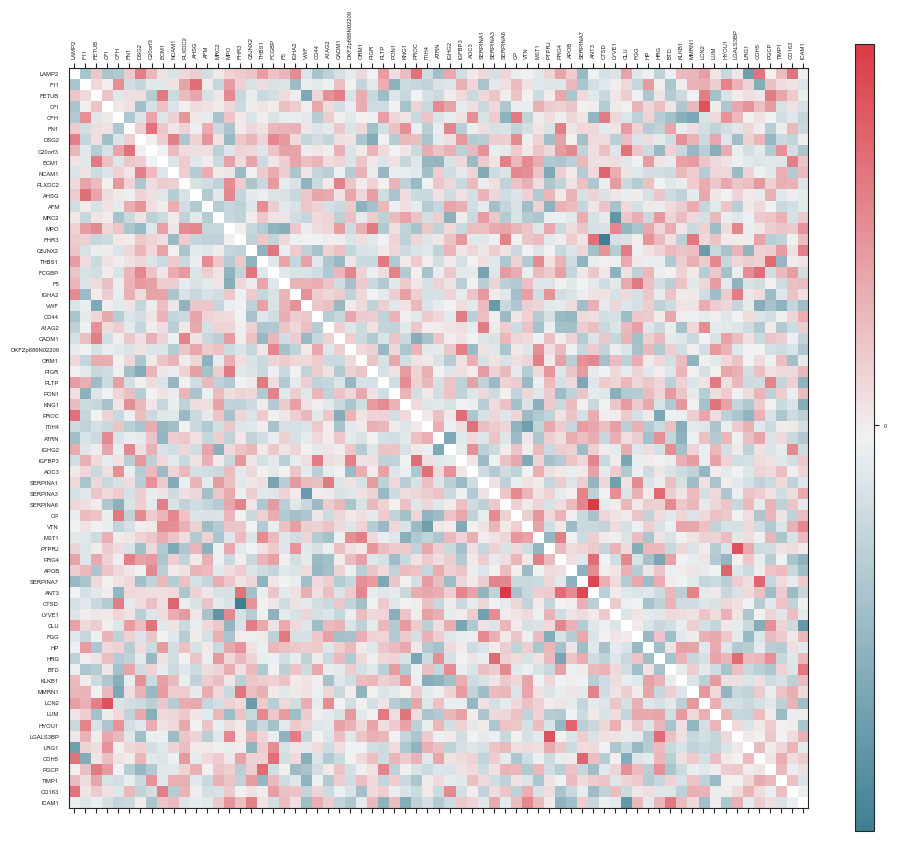

In [11]:
simpp0 = simpp0.reindex(columns, axis=1)
plot_corr(simpp0,size=10)

#### Correlation for TVAE healthy

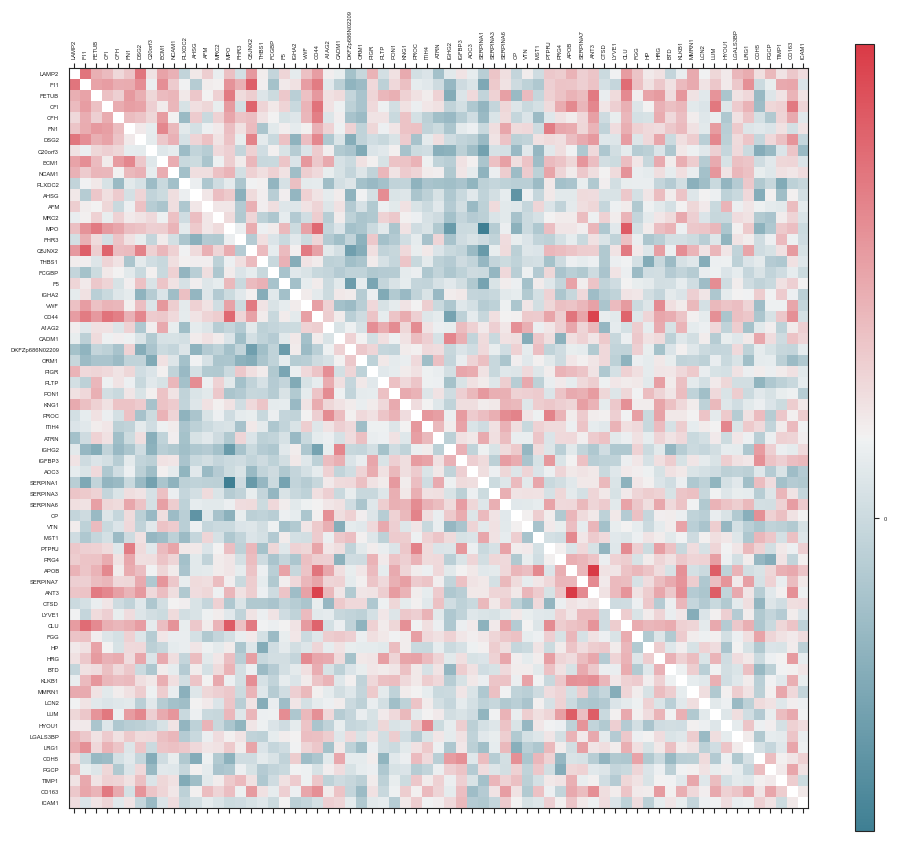

In [12]:
simtvae0 = simtvae0.reindex(columns, axis=1)
plot_corr(simtvae0,size=10)

#### Correlation for Copula healthy

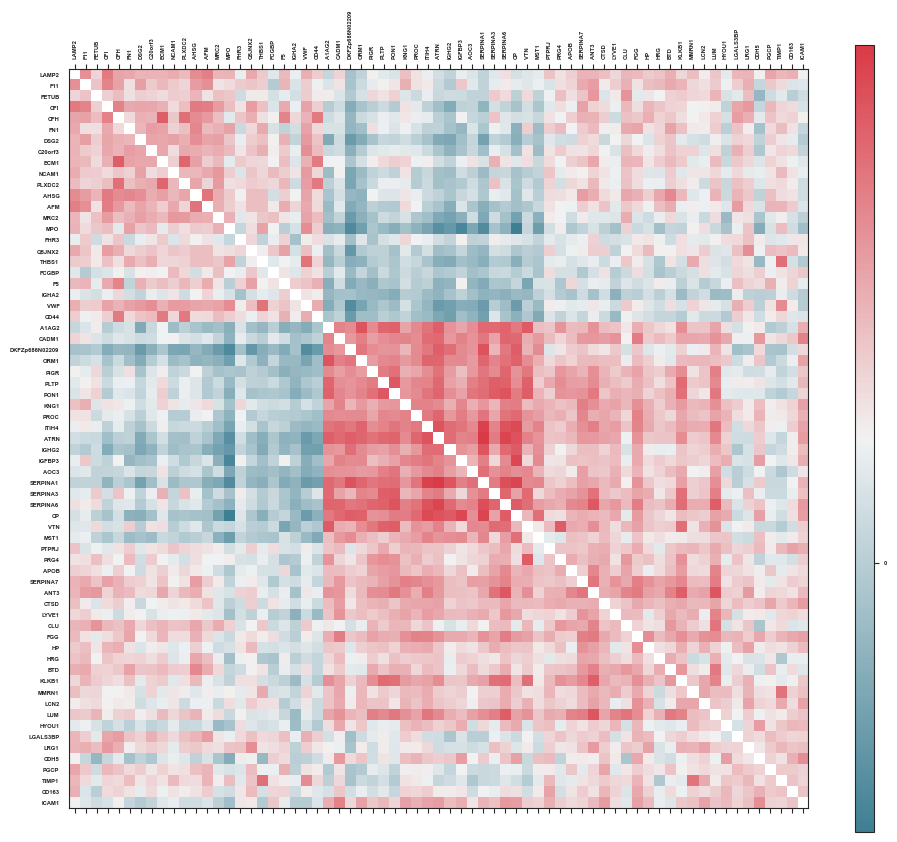

In [40]:
simco0 = simco0.reindex(columns, axis=1)
plot_corr(simco0,size=10)

#### Correlation for experimental data CRC

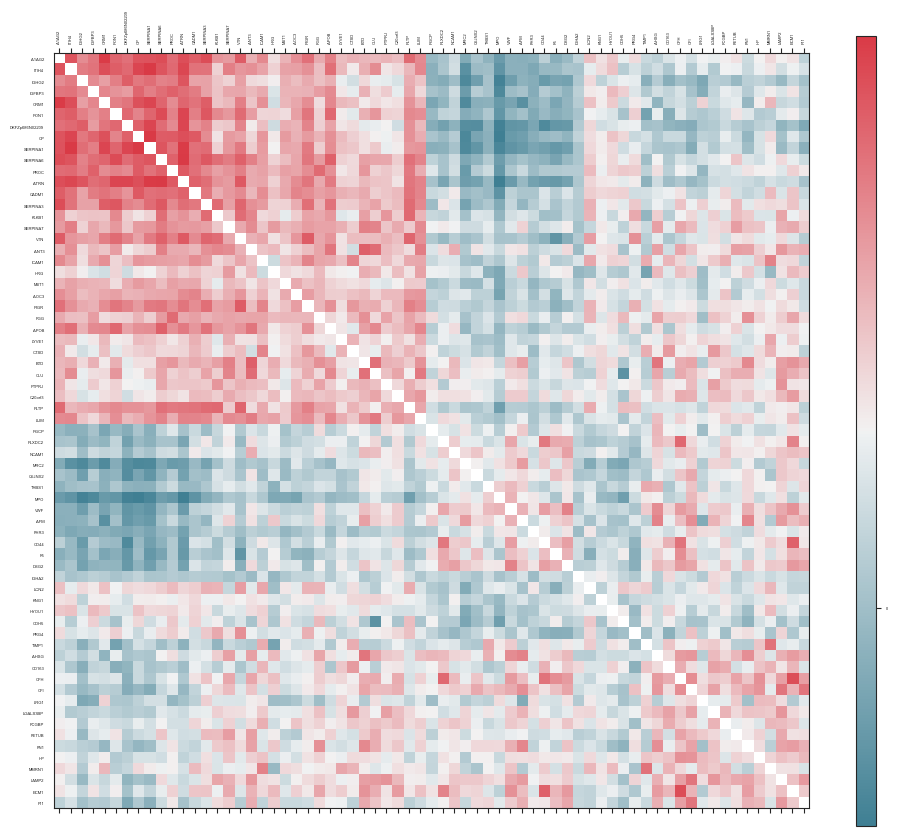

In [14]:
df = df_with_1
X = df.corr().values
X[np.isnan(X)]= 0
d = sch.distance.pdist(X)   
L = sch.linkage(d, method='complete')
ind = sch.fcluster(L, 0.5*d.max(), 'distance')
columns = [df.columns.tolist()[i] for i in list((np.argsort(ind)))]
df = df.reindex(columns, axis=1)
plot_corr(df, size=10,font_scale=0.5)

#### Correlation for Per-protein CRC

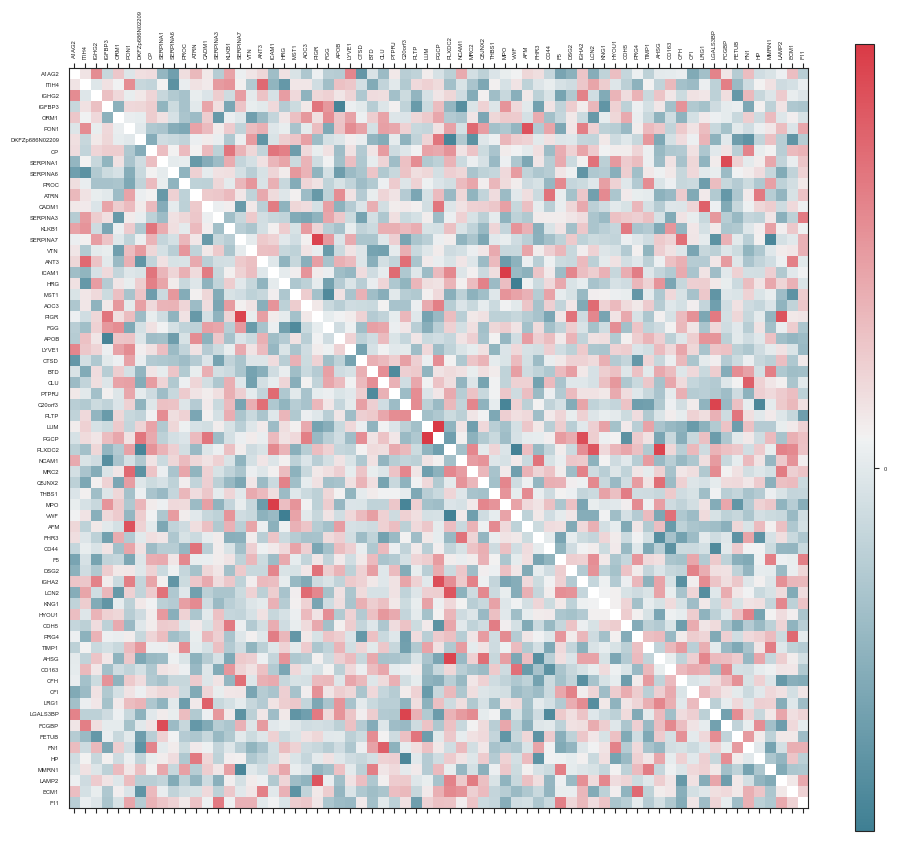

In [15]:
simpp1 = simpp1.reindex(columns, axis=1)
plot_corr(simpp1,size=10)

#### Correlation for TVAE CRC

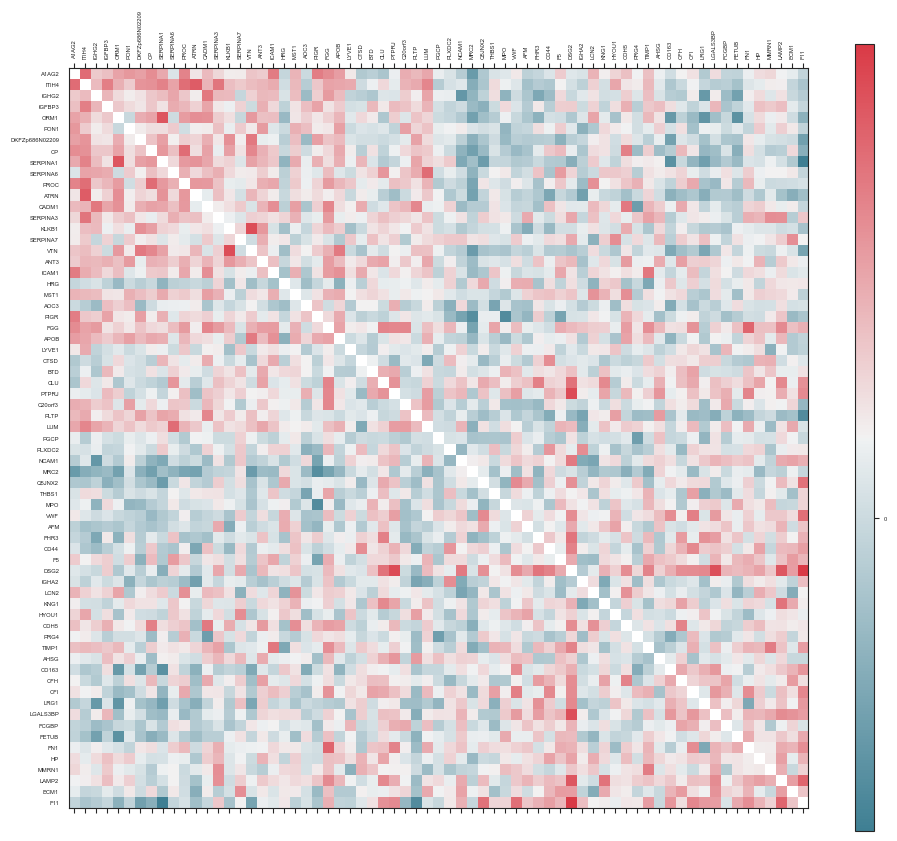

In [16]:
simtvae1 = simtvae1.reindex(columns, axis=1)
plot_corr(simtvae1,size=10)


#### Correlation for Copula CRC

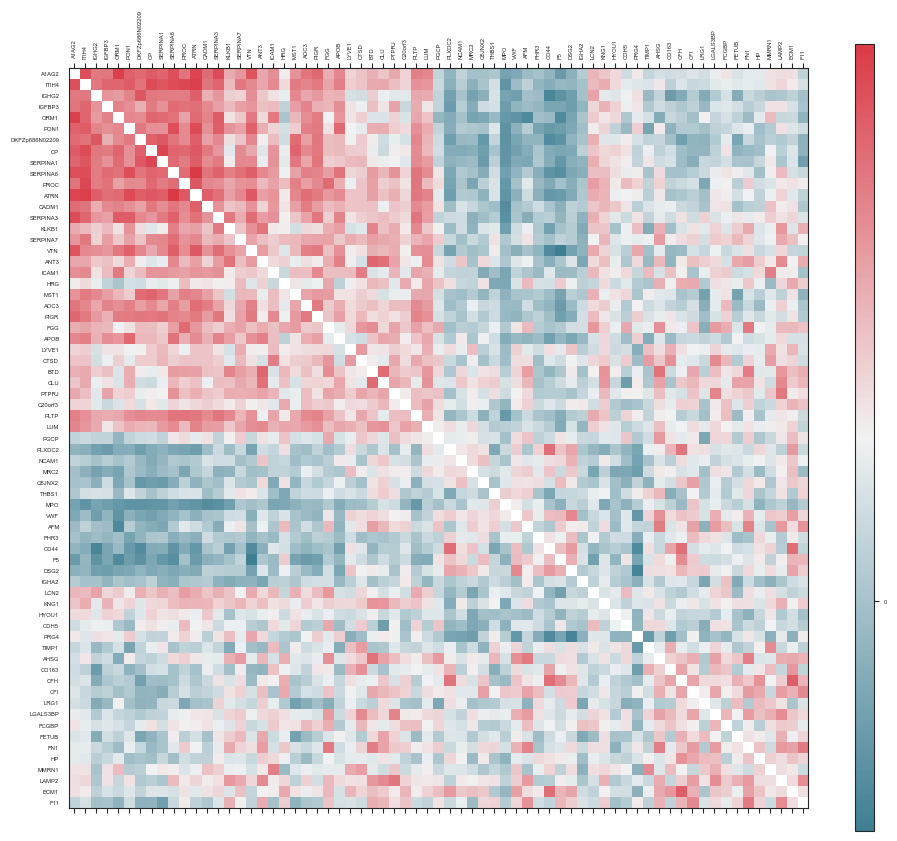

In [17]:
simco1 = simco1.reindex(columns, axis=1)
plot_corr(simco1,size=10)

#### Class Prediction

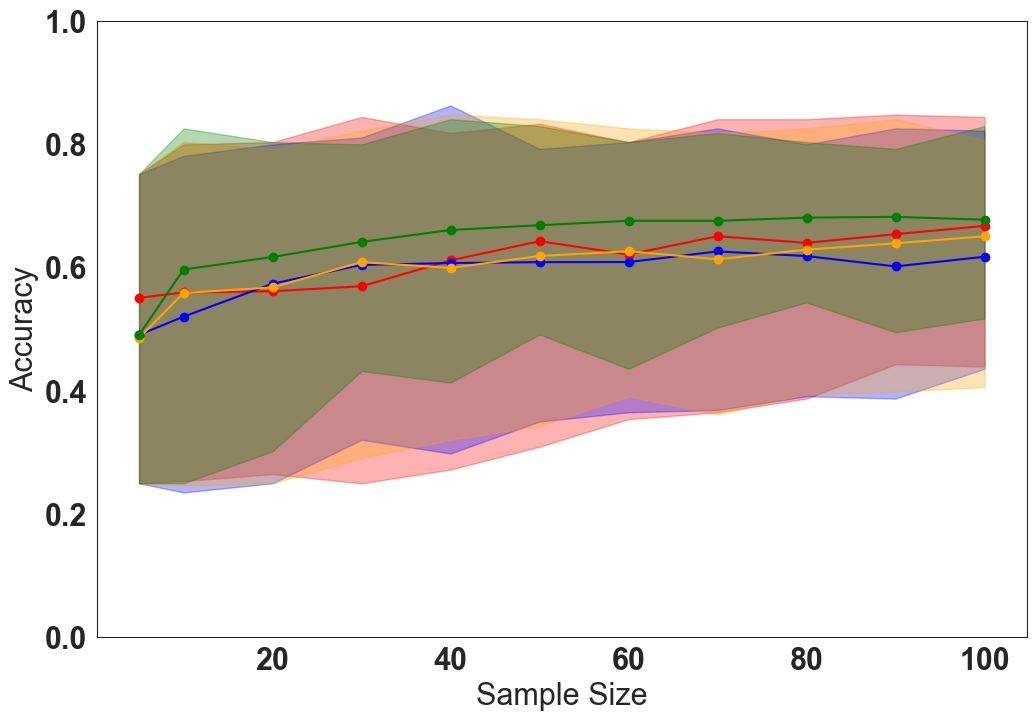

In [18]:
rfaccuracy = pd.read_csv('../casestudy/crc/crcrfaccuracynorm.csv')

crc_data_val = rfaccuracy
# Plotting
# matplotlib.rcParams.update({'font.size': 22})
font = {'weight' : 'bold',
        'size'   : 22}

matplotlib.rc('font', **font)

plt.figure(figsize=(12, 8))
# Plot REAL
plt.plot(crc_data_val['Sample Size'], crc_data_val['Accuracy'],label='Experimental',marker='o', color='red')
plt.fill_between(crc_data_val['Sample Size'], crc_data_val['min'], crc_data_val['max'], color='red', alpha=0.3)


# Plot PP
plt.plot(crc_data_val['Sample Size'], crc_data_val['PP Accuracy'], label='PP',marker='o', color='blue')
plt.fill_between(crc_data_val['Sample Size'], crc_data_val['PP min'], crc_data_val['PP max'], color='blue', alpha=0.3)

# Plot CO
plt.plot(crc_data_val['Sample Size'], crc_data_val['CO Accuracy'], label='CO',marker='o', color='orange')
plt.fill_between(crc_data_val['Sample Size'], crc_data_val['CO min'], crc_data_val['CO max'], color='orange', alpha=0.3)


# Plot TVAE
plt.plot(crc_data_val['Sample Size'], crc_data_val['TVAE Accuracy'], label='TVAE',marker='o', color='green')
plt.fill_between(crc_data_val['Sample Size'], crc_data_val['TVAE min'], crc_data_val['TVAE max'], color='green', alpha=0.3)

# Labels and legend
plt.xlabel('Sample Size')
plt.ylabel('Accuracy')
plt.ylim(0, 1) 

plt.show()


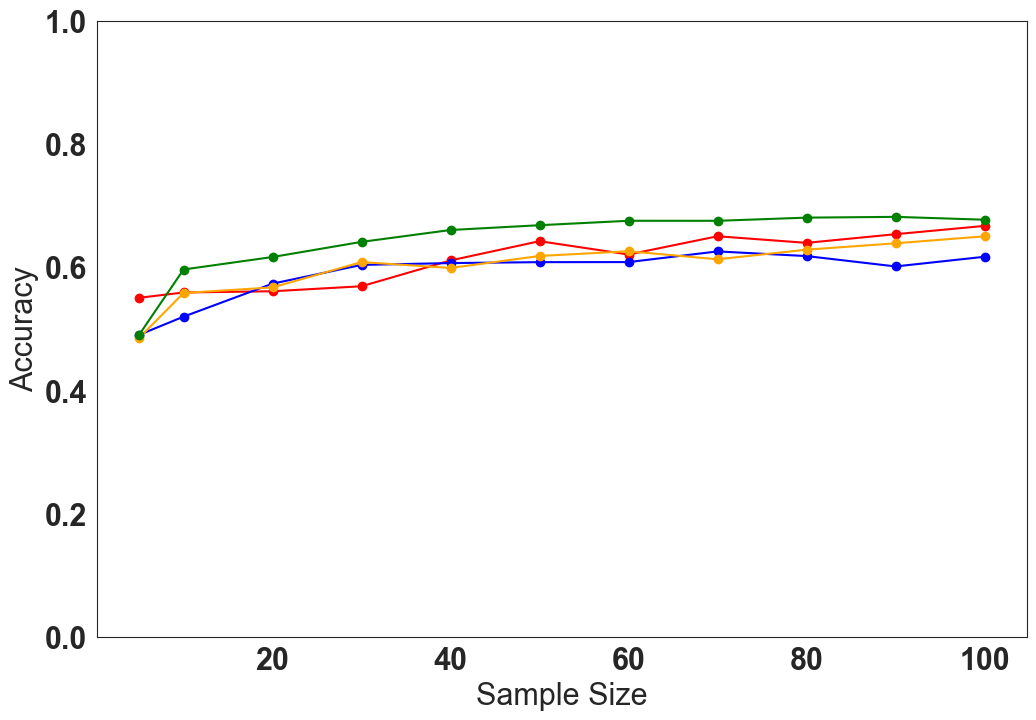

In [19]:
crc_data_val = rfaccuracy
# Plotting
# matplotlib.rcParams.update({'font.size': 22})
font = {'weight' : 'bold',
        'size'   : 22}

matplotlib.rc('font', **font)

plt.figure(figsize=(12, 8))
# Plot REAL
plt.plot(crc_data_val['Sample Size'], crc_data_val['Accuracy'],label='Experimental',marker='o', color='red')
# plt.fill_between(crc_data_val['Sample Size'], crc_data_val['min'], crc_data_val['max'], color='red', alpha=0.3)


# Plot PP
plt.plot(crc_data_val['Sample Size'], crc_data_val['PP Accuracy'], label='PP',marker='o', color='blue')
# plt.fill_between(crc_data_val['Sample Size'], crc_data_val['PP min'], crc_data_val['PP max'], color='blue', alpha=0.3)

# Plot CO
plt.plot(crc_data_val['Sample Size'], crc_data_val['CO Accuracy'], label='CO',marker='o', color='orange')
# plt.fill_between(crc_data_val['Sample Size'], crc_data_val['CO min'], crc_data_val['CO max'], color='orange', alpha=0.3)


# Plot TVAE
plt.plot(crc_data_val['Sample Size'], crc_data_val['TVAE Accuracy'], label='TVAE',marker='o', color='green')
# plt.fill_between(crc_data_val['Sample Size'], crc_data_val['TVAE min'], crc_data_val['TVAE max'], color='green', alpha=0.3)

# Labels and legend
plt.xlabel('Sample Size')
plt.ylabel('Accuracy')
# plt.title('Accuracy vs Sample Size for Different Methods')
# plt.legend()
# plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
# Show plot
# plt.grid(True)
plt.ylim(0, 1) 

plt.show()


##### Class Discovery

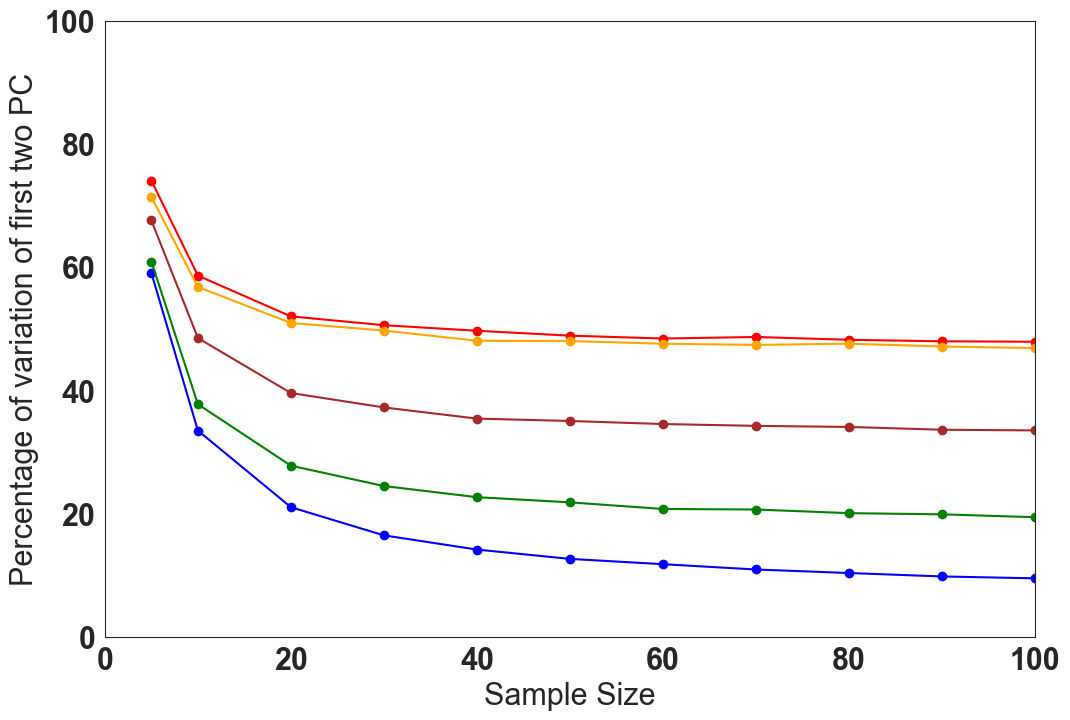

In [20]:
pcaaccuracy = pd.read_csv('../casestudy/crc/crcpca.csv')
crc_data_val = pcaaccuracy
# Plotting
# matplotlib.rcParams.update({'font.size': 22})
font = {'weight' : 'bold',
        'size'   : 22}

matplotlib.rc('font', **font)

plt.figure(figsize=(12, 8))
# Plot REAL
plt.plot(crc_data_val['Sample Size'], crc_data_val['Accuracy'],label='Experimental',marker='o', color='red')
# plt.fill_between(crc_data_val['Sample Size'], crc_data_val['min'], crc_data_val['max'], color='red', alpha=0.3)

plt.plot(crc_data_val['Sample Size'], crc_data_val['Accuracy v'],label='Experimental Validation',marker='o', color='brown')
# plt.fill_between(crc_data_val['Sample Size'], crc_data_val['min v'], crc_data_val['max v'], color='brown', alpha=0.3)


# Plot PP
plt.plot(crc_data_val['Sample Size'], crc_data_val['PP Accuracy'], label='PP',marker='o', color='blue')
# plt.fill_between(crc_data_val['Sample Size'], crc_data_val['PP min'], crc_data_val['PP max'], color='blue', alpha=0.3)

# Plot CO
plt.plot(crc_data_val['Sample Size'], crc_data_val['CO Accuracy'], label='CO',marker='o', color='orange')
# plt.fill_between(crc_data_val['Sample Size'], crc_data_val['CO min'], crc_data_val['CO max'], color='orange', alpha=0.3)


# Plot TVAE
plt.plot(crc_data_val['Sample Size'], crc_data_val['TVAE Accuracy'], label='TVAE',marker='o', color='green')
# plt.fill_between(crc_data_val['Sample Size'], crc_data_val['TVAE min'], crc_data_val['TVAE max'], color='green', alpha=0.3)

# Labels and legend
plt.xlabel('Sample Size')
plt.ylabel('Percentage of variation of first two PC')

plt.ylim(0, 100)
plt.xlim(0,100)
plt.show()


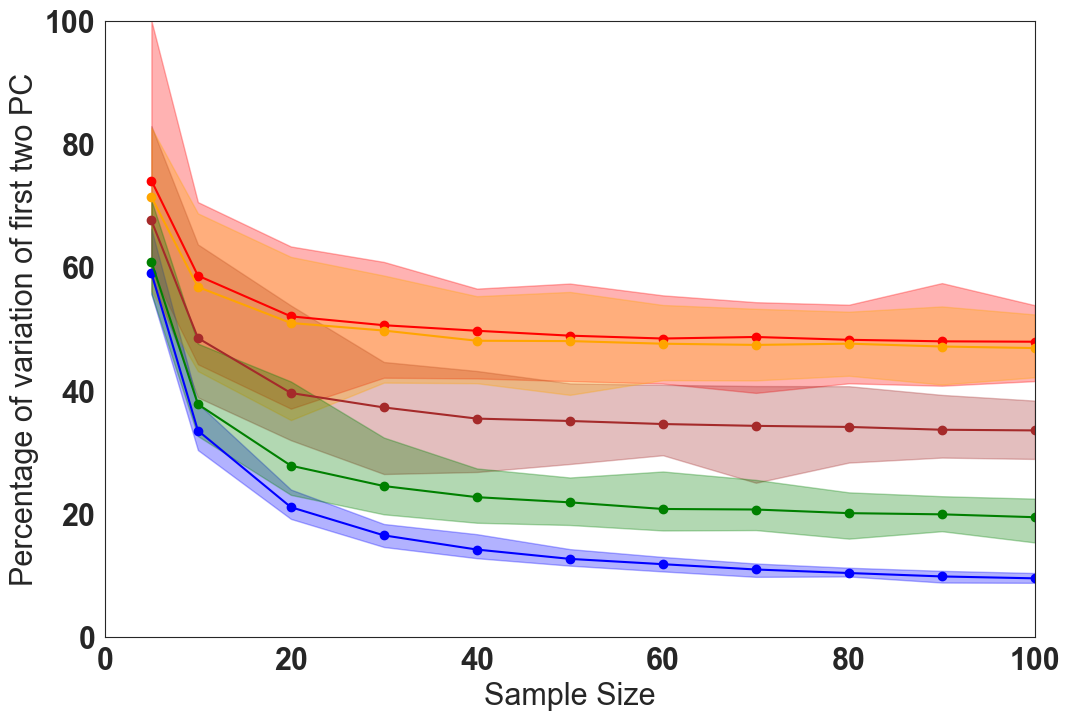

In [21]:
font = {'weight' : 'bold',
        'size'   : 22}

matplotlib.rc('font', **font)

plt.figure(figsize=(12, 8))
# Plot REAL
plt.plot(crc_data_val['Sample Size'], crc_data_val['Accuracy'],label='Experimental',marker='o', color='red')
plt.fill_between(crc_data_val['Sample Size'], crc_data_val['min'], crc_data_val['max'], color='red', alpha=0.3)

plt.plot(crc_data_val['Sample Size'], crc_data_val['Accuracy v'],label='Experimental Validation',marker='o', color='brown')
plt.fill_between(crc_data_val['Sample Size'], crc_data_val['min v'], crc_data_val['max v'], color='brown', alpha=0.3)


# Plot PP
plt.plot(crc_data_val['Sample Size'], crc_data_val['PP Accuracy'], label='PP',marker='o', color='blue')
plt.fill_between(crc_data_val['Sample Size'], crc_data_val['PP min'], crc_data_val['PP max'], color='blue', alpha=0.3)

# Plot CO
plt.plot(crc_data_val['Sample Size'], crc_data_val['CO Accuracy'], label='CO',marker='o', color='orange')
plt.fill_between(crc_data_val['Sample Size'], crc_data_val['CO min'], crc_data_val['CO max'], color='orange', alpha=0.3)


# Plot TVAE
plt.plot(crc_data_val['Sample Size'], crc_data_val['TVAE Accuracy'], label='TVAE',marker='o', color='green')
plt.fill_between(crc_data_val['Sample Size'], crc_data_val['TVAE min'], crc_data_val['TVAE max'], color='green', alpha=0.3)

# Labels and legend
plt.xlabel('Sample Size')
plt.ylabel('Percentage of variation of first two PC')

plt.ylim(0, 100)
plt.xlim(0,100)
plt.show()


##### Class Comparison

In [22]:
adjusted_p_values = {}
adjusted_p_values_pp = {}
adjusted_p_values_co = {}
adjusted_p_values_tvae = {}
dicts = {'real_adjust': adjusted_p_values, 'pp_adjust': adjusted_p_values_pp, 'co_adjust': adjusted_p_values_co, 'tvae_adjust': adjusted_p_values_tvae}  # Add more dictionaries as needed

# Load each JSON file and update the corresponding dictionary
for key, value in dicts.items():
    file_path = f'../casestudy/crc/pval/{key}.json'
    with open(file_path, 'r') as json_file:
        value.update(json.load(json_file))

sample_sizes=[5,10,15,20,25,30,35,40,45,50,55,60,65,70,75,80,85,90,95,100]

real = []
pp = []
co = []
tvae = []
realmin = []
realmax = []
ppmin = []
ppmax = []
comin = []
comax = []
tvaemin = []
tvaemax = []

col = 'CP'

for s in sample_sizes:
    s = str(s)
    real.append(np.median(adjusted_p_values[s][col]))
    pp.append(np.median(adjusted_p_values_pp[s][col]))
    co.append(np.median(adjusted_p_values_co[s][col]))
    tvae.append(np.median(adjusted_p_values_tvae[s][col]))
    realmin.append(np.min(adjusted_p_values[s][col]))
    realmax.append(np.max(adjusted_p_values[s][col]))
    ppmin.append(np.min(adjusted_p_values_pp[s][col]))
    ppmax.append(np.max(adjusted_p_values_pp[s][col]))
    comin.append(np.min(adjusted_p_values_co[s][col]))
    comax.append(np.max(adjusted_p_values_co[s][col])) 
    tvaemin.append(np.min(adjusted_p_values_tvae[s][col]))
    tvaemax.append(np.max(adjusted_p_values_tvae[s][col]))


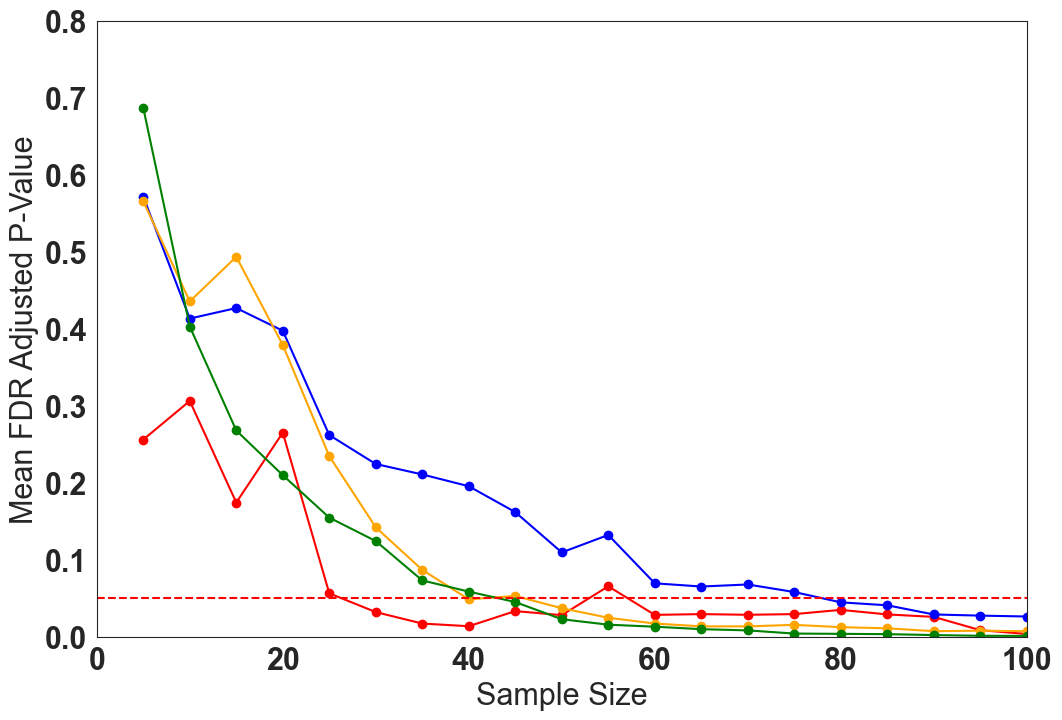

In [23]:
plt.figure(figsize=(12, 8))
font = {'weight' : 'bold',
        'size'   : 22}

matplotlib.rc('font', **font)
plt.plot(sample_sizes, real, marker='o', label='Experimental', color='red', linestyle='-')
# plt.fill_between(sample_sizes, realmin, realmax, color='red', alpha=0.3)

plt.plot(sample_sizes, pp, marker='o', label='Per-Protein', color='blue', linestyle='-')
# plt.fill_between(sample_sizes, ppmin, ppmax, color='blue', alpha=0.3)

plt.plot(sample_sizes, co, marker='o', label='Copula', color='orange', linestyle='-')
# plt.fill_between(sample_sizes, comin, comax, color='orange', alpha=0.3)

plt.plot(sample_sizes, tvae, marker='o', label='TVAE', color='green', linestyle='-')
# plt.fill_between(sample_sizes, tvaemin, tvaemax, color='green', alpha=0.3)

plt.axhline(y=0.05, color='red', linestyle='--')

plt.xlabel('Sample Size')
plt.ylabel('Mean FDR Adjusted P-Value')

plt.ylim(0.0,0.8)
plt.xlim(0,100)
plt.show()

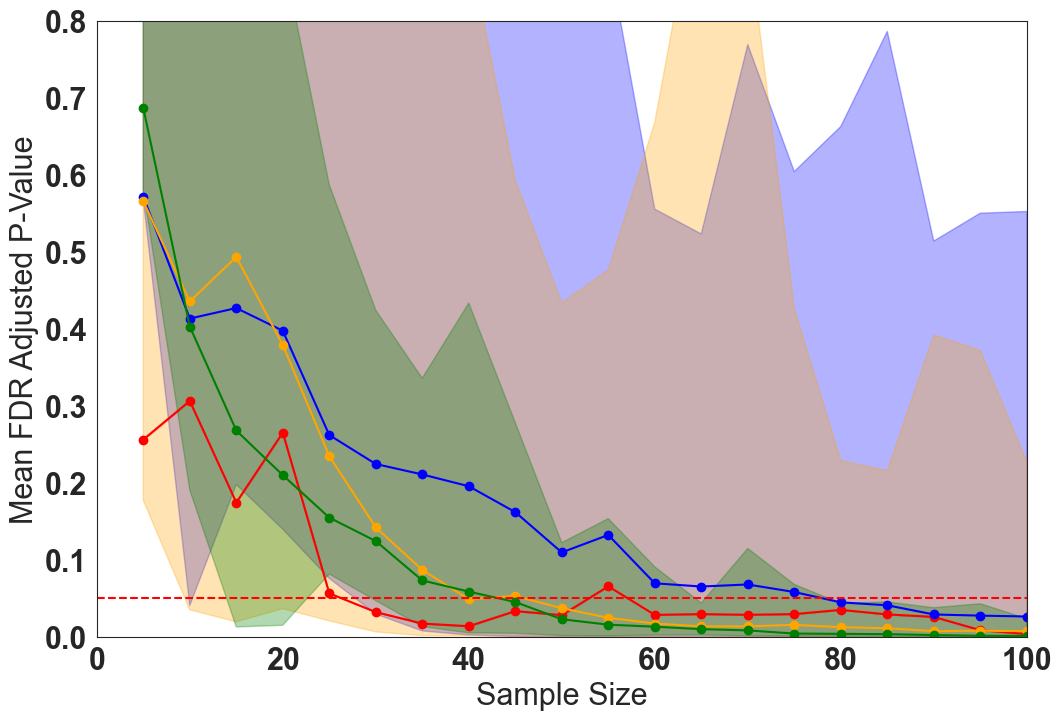

In [24]:
plt.figure(figsize=(12, 8))
font = {'weight' : 'bold',
        'size'   : 22}

matplotlib.rc('font', **font)
plt.plot(sample_sizes, real, marker='o', label='Experimental', color='red', linestyle='-')
plt.fill_between(sample_sizes, realmin, realmax, color='red', alpha=0.3)

plt.plot(sample_sizes, pp, marker='o', label='Per-Protein', color='blue', linestyle='-')
plt.fill_between(sample_sizes, ppmin, ppmax, color='blue', alpha=0.3)

plt.plot(sample_sizes, co, marker='o', label='Copula', color='orange', linestyle='-')
plt.fill_between(sample_sizes, comin, comax, color='orange', alpha=0.3)

plt.plot(sample_sizes, tvae, marker='o', label='TVAE', color='green', linestyle='-')
plt.fill_between(sample_sizes, tvaemin, tvaemax, color='green', alpha=0.3)

plt.axhline(y=0.05, color='red', linestyle='--')

plt.xlabel('Sample Size')
plt.ylabel('Mean FDR Adjusted P-Value')

plt.ylim(0.0,0.8)
plt.xlim(0,100)
plt.show()